In [1]:
from II_funcs import *
import corner
import re
plt.rcParams['mathtext.fontset'] =  "cm"
plt.rcParams['font.family'] =  "serif"
plt.rcParams['mathtext.default']='regular'

from IPython.display import FileLink
import gc
from scipy.interpolate import RectBivariateSpline
from scipy.interpolate import RegularGridInterpolator
from scipy.stats import linregress
from astropy import units as u
import pandas as pd

theta_E_1 = np.array([np.sqrt(4 * G * .1*(2e33) / c**2 * D_ls / (D_s * D_l))])
theta_E_8 = np.array([np.sqrt(4 * G * .8*(2e33) / c**2 * D_ls / (D_s * D_l))])

data=np.load('data/macro_lens_results.npz')
mag_fit=6.86
B_matrix=data['inv_jacobian_fit'][0]
phi_0=-2.07858699980682

In [2]:
#define image specific constants, these don't change within this file
theta_max = 2e-10 # (half) size of image
image_size=7000
N_step = image_size
#theta_max = 0.7e-10
g_params=(kappa_bulk, gamma1, gamma2)
theta_step = 2 * theta_max / image_size
vec_theta = np.linspace(-theta_max, theta_max, N_step)
arr_theta = np.asarray(np.meshgrid(vec_theta, vec_theta, indexing='xy'))
beta_min = .9e-11
rad = theta_500  
rad_mas=rad*rad_to_arcsec
g_params = (kappa_bulk, gamma1, gamma2)
sigma_C = error_C(mag=16.5, wavelength=500*1e-7, R = 2e4, sigma_t=3e-12, A=10*(500**2)*np.pi, t_obs= 8 * 3600)

In [3]:
def rotate_data_pos(xpts, ypts, theta):
    "xpts, ypts are relative to 0 0 in the right bottom corner of the image. theta in radians"
    xpts=np.array(xpts)
    ypts=np.array(ypts)
    xpts=xpts-0.5
    ypts=ypts-0.5
    rs=np.sqrt(xpts**2+ypts**2)
    x2=rs*np.cos(np.arctan2(xpts, ypts)+theta)
    y2=rs*np.sin(np.arctan2(xpts, ypts)+theta)
    return x2, y2

def load_file(file, skip_lines=0, matrix=True, force_shape=(4,4)):
    """
    Parse file with entries where each entry has a header (5 or 6 numeric tokens)
    followed by a matrix block between [[ and ]].
    Returns:
      out_xval: (N,2) array (second column nan if header had single x)
      out_rad, out_mass, out_x, out_y: 1D arrays length N
      out_mat: list of numpy arrays (each either reshaped to force_shape if possible, else 1D)
    """
    # token regex matches floats (with optional exp), ints, or 'nan'
    token_re = re.compile(r'[-+]?\d*\.\d+(?:[eE][-+]?\d+)?|[-+]?\d+|nan', flags=re.I)
    with open(file, 'r') as fh:
        lines = fh.readlines()[skip_lines:]
    raw = "".join(lines)

    out_x1, out_x2 = [], []
    out_rad, out_mass, out_x, out_y = [], [], [], []
    out_mat = []

    # find all matrix blocks; iterate in order and take header as text since previous end
    prev_end = 0
    for m in re.finditer(r'\[\[.*?\]\]', raw, flags=re.S):
        header_text = raw[prev_end:m.start()].strip()
        matrix_text = m.group()
        prev_end = m.end()

        # extract numeric-ish tokens from header (includes 'nan')
        header_tokens = token_re.findall(header_text)
        if not header_tokens:
            raise ValueError(f"No numeric tokens found in header preceding matrix at pos {m.start()}")

        # convert tokens to floats, treating 'nan' correctly
        def tok_to_float(t):
            return np.nan if t.lower() == 'nan' else float(t)
        header_vals = [tok_to_float(t) for t in header_tokens]

        # map header tokens -> fields (6-token or 5-token)
        if len(header_vals) == 6:
            x1, x2, rad, mass, xpos, ypos = header_vals
        elif len(header_vals) == 5:
            x1, x2 = header_vals[0], np.nan
            rad, mass, xpos, ypos = header_vals[1], header_vals[2], header_vals[3], header_vals[4]
        else:
            raise ValueError(
                f"Unexpected number of header tokens ({len(header_vals)}) found: {header_tokens!r}\n"
                "Expected 5 or 6 tokens."
            )

        out_x1.append(x1)
        out_x2.append(x2)
        out_rad.append(rad)
        out_mass.append(mass)
        out_x.append(xpos)
        out_y.append(ypos)

        if matrix:
            mat_tokens = token_re.findall(matrix_text)
            if not mat_tokens:
                mat_arr = np.array([], dtype=float)
            else:
                mat_vals = [tok_to_float(t) for t in mat_tokens]
                mat_arr = np.array(mat_vals, dtype=float)
                # reshape if shape matches force_shape
                if force_shape is not None and mat_arr.size == np.prod(force_shape):
                    mat_arr = mat_arr.reshape(force_shape)
            out_mat.append(mat_arr)

    # if there was trailing text after last matrix containing another valid entry without matrix,
    # it won't be processed. That's intentional: function associates matrices with preceding headers.

    out_xval = np.column_stack([np.array(out_x1, dtype=float), np.array(out_x2, dtype=float)])
    return (out_xval,
            np.array(out_rad, dtype=float),
            np.array(out_mass, dtype=float),
            np.array(out_x, dtype=float),
            np.array(out_y, dtype=float),
            out_mat if matrix else None)
    
def load_mag_file(file, skip_lines=0, matrix=True, force_shape=(4,4)):
    """
    Parse file with entries where each entry has a header (5 or 6 numeric tokens)
    followed by a matrix block between [[ and ]].
    Returns:
      out_xval: (N,2) array (second column nan if header had single x)
      out_rad, out_mass, out_x, out_y: 1D arrays length N
      out_mat: list of numpy arrays (each either reshaped to force_shape if possible, else 1D)
    """
    # token regex matches floats (with optional exp), ints, or 'nan'
    token_re = re.compile(r'[-+]?\d*\.\d+(?:[eE][-+]?\d+)?|[-+]?\d+|nan', flags=re.I)
    with open(file, 'r') as fh:
        lines = fh.readlines()[skip_lines:]
    raw = "".join(lines)

    out_x1, out_x2 = [], []
    out_mat = []

    # find all matrix blocks; iterate in order and take header as text since previous end
    prev_end = 0
    for m in re.finditer(r'\[\[.*?\]\]', raw, flags=re.S):
        header_text = raw[prev_end:m.start()].strip()
        matrix_text = m.group()
        prev_end = m.end()

        # extract numeric-ish tokens from header (includes 'nan')
        header_tokens = token_re.findall(header_text)
        if not header_tokens:
            raise ValueError(f"No numeric tokens found in header preceding matrix at pos {m.start()}")

        # convert tokens to floats, treating 'nan' correctly
        def tok_to_float(t):
            return np.nan if t.lower() == 'nan' else float(t)
        header_vals = [tok_to_float(t) for t in header_tokens]

        # map header tokens -> fields (6-token or 5-token)
        if len(header_vals) == 2:
            x1, x2 = header_vals
        if len(header_vals) == 1:
            x1 = header_vals
            x2=0
        #elif len(header_vals) == 5:
        #    x1, x2 = header_vals[0], np.nan
        #    rad, mass, xpos, ypos = header_vals[1], header_vals[2], header_vals[3], header_vals[4]
        #else:
        #    raise ValueError(
        #        f"Unexpected number of header tokens ({len(header_vals)}) found: {header_tokens!r}\n"
        #        "Expected 5 or 6 tokens."
        #    )

        out_x1.append(x1)
        out_x2.append(x2)

        if matrix:
            mat_tokens = token_re.findall(matrix_text)
            if not mat_tokens:
                mat_arr = np.array([], dtype=float)
            else:
                mat_vals = [tok_to_float(t) for t in mat_tokens]
                mat_arr = np.array(mat_vals, dtype=float)
                # reshape if shape matches force_shape
                if force_shape is not None and mat_arr.size == np.prod(force_shape):
                    mat_arr = mat_arr.reshape(force_shape)
            out_mat.append(mat_arr)

    # if there was trailing text after last matrix containing another valid entry without matrix,
    # it won't be processed. That's intentional: function associates matrices with preceding headers.
    if np.array(out_x2).any!=0:
        out_xval = np.column_stack([np.array(out_x1, dtype=float), np.array(out_x2, dtype=float)])
    else:
        out_xval = np.column_stack([np.array(out_x1, dtype=float)])
    return (out_xval,
            out_mat if matrix else None)

def load_cents(file):
    centroids=[]
    positions=[]
    with open(file, 'r') as fh:
        lines = fh.readlines()[:]
        for i in range(len(lines)):
            
            positions.append(np.array((float(lines[i].split(']')[0].split('[')[1].split(' ')[0]), 
                                       float(lines[i].split(']')[0].split('[')[1].split(' ')[1]))))
            J0=(np.array((float((lines[i].split(']')[1].split('[[')[1]).split(',')[0]), 
                                           float((lines[i].split(']')[1].split('[[')[1]).split(',')[1]))))
            J1=(np.array((float((lines[i].split(']')[3].split('[[')[1]).split(',')[0]), 
                                           float((lines[i].split(']')[3].split('[[')[1]).split(',')[1]))))
            J2=(np.array((float((lines[i].split(']')[5].split('[[')[1]).split(',')[0]), 
                                           float((lines[i].split(']')[5].split('[[')[1]).split(',')[1]))))
            J3=(np.array((float((lines[i].split(']')[7].split('[[')[1]).split(',')[0]), 
                                           float((lines[i].split(']')[7].split('[[')[1]).split(',')[1]))))

            J_cent=np.vstack([J0, J1, J2, J3]).T
            centroids.append(J_cent)

    return (np.array(positions), np.array(centroids))
    

def get_combo_cov(fisher_mag, cov_II, theta_step_mag, theta_step_II, numstars):
    # Convert cov_II to Fisher
    fisher_II = jnp.linalg.inv(cov_II.reshape(1+3*numstars, 1+3*numstars))

    # Rescale both to radians
    fisher_mag_rescaled = rescale_fisher_to_radians(fisher_mag, theta_step_mag, numstars)
    fisher_II_rescaled  = rescale_fisher_to_radians(fisher_II, theta_step_II, numstars)

    # Combine
    fisher_tot = fisher_mag_rescaled + fisher_II_rescaled

    # Final covariance + uncertainties (now in radians)
    cov_tot, uncertainties_tot = parameter_uncertainties(
        fisher_tot,
        theta_step=1.0,   # already in radians, no further scaling
        printout=False,
        numstars=numstars
    )

    return cov_tot, uncertainties_tot

def rescale_fisher_to_radians(F, theta_step, numstars):
    n_params = 1 + 3*numstars
    J = jnp.eye(n_params)

    # indices
    x_start = 1 + numstars
    y_start = 1 + 2*numstars

    # scale x and y
    J = J.at[x_start:x_start+numstars, x_start:x_start+numstars].set(theta_step)
    J = J.at[y_start:y_start+numstars, y_start:y_start+numstars].set(theta_step)

    # transform Fisher matrix
    return J.T @ F @ J

def load_chi2s(file, skip_lines=0):
    """
    get chi2s from file
    """
    # token regex matches floats (with optional exp), ints, or 'nan'
    token_re = re.compile(r'[-+]?\d*\.\d+(?:[eE][-+]?\d+)?|[-+]?\d+|nan', flags=re.I)
    with open(file, 'r') as fh:
        lines = fh.readlines()[skip_lines:]
    raw = "".join(lines)
    out_chis = []
    for line in lines:
        header_tokens = token_re.findall(line)
        if not header_tokens:
            raise ValueError(f"No numeric tokens found in header preceding matrix at pos {m.start()}")
        if len(header_tokens) == 3:
            x1, x2, chi = header_tokens        
        out_chis.append(chi)
    return np.array(out_chis, dtype=float)

def get_velocities(v_rest, B_matrix, redshift, lens_dist):
    """
    Inputs
        v_rest: velocity of the star in the lens plane in the same units at lens_dist/unit time
        redshift: redshift of lens (star)
        lens_dist: angular diameter distance to lens
        B_matrix: macrolensing matrix, inv_jacobian_fit
    Returns the lensed proper motion of the star in radians 
    """
    mu_rest = v_rest /(1 + redshift) * (1 / lens_dist) 
    mu_x = mu_rest[0] * B_matrix[0, 0] + mu_rest[1] * B_matrix[0, 1]
    mu_y = mu_rest[0] * B_matrix[1, 0] + mu_rest[1] * B_matrix[1, 1]
    return np.array((mu_x, mu_y))
    
def rescale_cov_to_radians(C, theta_step, numstars):
    n_params = 1 + 3*numstars
    J = jnp.eye(n_params)

    # indices
    x_start = 1 + numstars
    y_start = 1 + 2*numstars

    # scale x and y
    J = J.at[x_start:x_start+numstars, x_start:x_start+numstars].set(theta_step)
    J = J.at[y_start:y_start+numstars, y_start:y_start+numstars].set(theta_step)

    return J @ C @ J.T


def sim_rand_traj(bulk_vel, bulk_vel_err, vel_disp, vel_disp_err, theta_max, N, redshift, lens_dist, B_matrix, dist, 
                  dt_days=182.0, max_time_days= 5 * 365.0):
    """
    Simulate a single star trajectory in radians on an image grid
    Returns dict {'times_days', 'positions_rad' (radians Nx2), 'pixel_indices' (Nx2 ints), 'initial_position_rad', 'velocity_kms}

    Inputs:
        bulk_vel: km/s, asusmed to be entirely in the x direction (arb)
        bulk_vel_err: km/s
        vel_disp: km/s, velocity dispersion of the lensing galaxy
        theta_max: image smapens -theta_max to theta_max in x and y, radians
        N: number of pixels
        redshift: redshift of star
        lens_dist: in cm 
        B_matrix: inv_jacobian of the macrolensing stuff
        dt_days: cadence in days
        max_time_days: safety if we get a slow star     
    Returns:
        times_Deays: 1D array
        positions_rad: Nx2 array in rad
        pixel_indices: Nx2, ints, -1 for outside image
    The star passes at closest approach (impact parameter) = dist at t = 0.
    We integrate forward and backward in time with cadence dt_days.

    """

    km_to_cm = 1e5
    day_to_sec = 86400.0
    dt_sec = dt_days * day_to_sec
    max_time_sec = max_time_days * day_to_sec

    total_span = 2.0 * theta_max
    pixel_size = total_span / N

    # vel in km/s
    tot_vel=np.sqrt(bulk_vel**2+vel_disp**2)
    vel_angle=np.random.uniform(0, 2 * np.pi)
    
    v_x_kms =np.cos(vel_angle)*tot_vel #(np.random.normal(loc=bulk_vel, scale=bulk_vel_err)
               #+ np.random.normal(loc=0, scale=np.sqrt(vel_disp**2 + vel_disp_err**2)))
    v_y_kms = np.sin(vel_angle)*tot_vel#np.random.normal(loc=0, scale=np.sqrt(vel_disp**2 + vel_disp_err**2))

    # to angular
    v_rest = np.array([v_x_kms, v_y_kms]) * km_to_cm #to match lens_dist units
    v_ang = get_velocities(v_rest, B_matrix, redshift, lens_dist)
    v_x_ang, v_y_ang = v_ang

    v_norm = np.hypot(v_x_ang, v_y_ang)
    if v_norm == 0:
        raise ValueError("Zero velocity — cannot define trajectory direction.")

    # position at closest approach
    # direction perpendicular to velocity vector
    #phi = np.random.uniform(0, 2 * np.pi)  # pick random orientation of velocity
    # rotate velocity vector by angle phi around center to randomize orientation
    # rot = np.array([[np.cos(phi), -np.sin(phi)], [np.sin(phi), np.cos(phi)]])
    #v_ang_rot = rot @ np.array([v_x_ang, v_y_ang])
    #v_x_ang, v_y_ang = v_ang_rot

    # perpendicular unit vector
    n_perp = np.array([-v_y_ang, v_x_ang]) / np.hypot(v_x_ang, v_y_ang)
    theta0 = dist * n_perp  # position at closest approach
    theta_x0, theta_y0 = theta0
    times = np.arange(-max_time_sec, max_time_sec + dt_sec, dt_sec)

    theta_x = theta_x0 + v_x_ang * times
    theta_y = theta_y0 + v_y_ang * times
    positions = np.column_stack([theta_x, theta_y])
    pix_x = np.floor((theta_x + theta_max) / pixel_size).astype(int)
    pix_y = np.floor((theta_y + theta_max) / pixel_size).astype(int)
    
    inside = (pix_x >= 0) & (pix_x < N) & (pix_y >= 0) & (pix_y < N)
    
    """
    if not np.all(inside):
        first_out = np.argmax(~inside)   # first False
        # truncate arrays
        times = times[:first_out]
        theta_x = theta_x[:first_out]
        theta_y = theta_y[:first_out]
        pix_x = pix_x[:first_out]
        pix_y = pix_y[:first_out]
    """
    
    outside_mask = (pix_x < 0) | (pix_x >= N) | (pix_y < 0) | (pix_y >= N)
    pix_x[outside_mask] = -1
    pix_y[outside_mask] = -1
    pixel_indices = np.column_stack([pix_x, pix_y])

    times_days = times / day_to_sec

    return {"times_days": times_days, "positions_rad": positions, "pixel_indices": pixel_indices,
        "closest_approach_rad": (theta_x0, theta_y0), "velocity_kms": (v_x_kms, v_y_kms),
        "proper_motion": (v_x_ang, v_y_ang)} # rad/s


### Functions for generating the interpolated functions

In [4]:
def one_quad_to_full(quad_arr, n):
    """
    Reflect a quadrants worth of data over the x and y axes to get the grid in all four
    """
    arr_quadrant = quad_arr.reshape(n, n)  # this is for x<0, y<0
    
    y_reflect = np.flipud(arr_quadrant)
    x_reflect = np.fliplr(arr_quadrant)
    xy_reflect = np.flipud(np.fliplr(arr_quadrant))
    
    right = np.concatenate((xy_reflect, y_reflect[:, 1:]), axis=1)
    left = np.concatenate((np.fliplr(arr_quadrant), np.fliplr(x_reflect)[:, 1:]), axis=1)
    
    return np.concatenate((right[:-1, :], left), axis=0)
    
def matrix_to_full(quad_arr, n):
    arr_quadrant = quad_arr.reshape(n, n, 4, 4)  # this is for x<0, y<0
    
    y_reflect = np.flipud(arr_quadrant)
    x_reflect = np.fliplr(arr_quadrant)
    xy_reflect = np.flipud(np.fliplr(arr_quadrant))
    
    right = np.concatenate((xy_reflect, y_reflect[:, 1:]), axis=1)
    left = np.concatenate((np.fliplr(arr_quadrant), np.fliplr(x_reflect)[:, 1:]), axis=1)
    
    return np.concatenate((right[:-1, :], left), axis=0)

def Jac_to_full(quad_arr, n):
    # quad_arr shape: (n, n, 2, 4)
    arr = quad_arr.reshape(n, n, 2, 4)

    y_reflect  = np.flipud(arr)
    x_reflect  = np.fliplr(arr)
    xy_reflect = np.flipud(np.fliplr(arr))

    right = np.concatenate((xy_reflect, y_reflect[:, 1:]), axis=1)
    left  = np.concatenate((np.fliplr(arr), np.fliplr(x_reflect)[:, 1:]), axis=1)

    full = np.concatenate((right[:-1, :], left), axis=0)

    return full


### Functions for post-processing

In [5]:
def get_velocities(v_rest, B_matrix, redshift, lens_dist):
    """
    Inputs
        v_rest: velocity of the star in the lens plane in the same units at lens_dist/unit time
        redshift: redshift of lens (star)
        lens_dist: angular diameter distance to lens
        B_matrix: macrolensing matrix, inv_jacobian_fit
    Returns the lensed proper motion of the star in radians 
    """
    mu_rest = v_rest /(1 + redshift) * (1 / lens_dist) 
    mu_x = mu_rest[0] * B_matrix[0, 0] + mu_rest[1] * B_matrix[0, 1]
    mu_y = mu_rest[0] * B_matrix[1, 0] + mu_rest[1] * B_matrix[1, 1]
    return np.array((mu_x, mu_y))


def sim_rand_traj(bulk_vel, bulk_vel_err, vel_disp, vel_disp_err, theta_max, N, redshift, lens_dist, B_matrix, dist, 
                  dt_days=182.0, max_time_days= 5 * 365.0):
    """
    Simulate a single star trajectory in radians on an image grid
    Returns dict {'times_days', 'positions_rad' (radians Nx2), 'pixel_indices' (Nx2 ints), 'initial_position_rad', 'velocity_kms}

    Inputs:
        bulk_vel: km/s, asusmed to be entirely in the x direction (arb)
        bulk_vel_err: km/s
        vel_disp: km/s, velocity dispersion of the lensing galaxy
        theta_max: image smapens -theta_max to theta_max in x and y, radians
        N: number of pixels
        redshift: redshift of star
        lens_dist: in cm 
        B_matrix: inv_jacobian of the macrolensing stuff
        dt_days: cadence in days
        max_time_days: safety if we get a slow star     
    Returns:
        times_Deays: 1D array
        positions_rad: Nx2 array in rad
        pixel_indices: Nx2, ints, -1 for outside image
    The star passes at closest approach (impact parameter) = dist at t = 0.
    We integrate forward and backward in time with cadence dt_days.

    """

    km_to_cm = 1e5
    day_to_sec = 86400.0
    dt_sec = dt_days * day_to_sec
    max_time_sec = max_time_days * day_to_sec

    total_span = 2.0 * theta_max
    pixel_size = total_span / N

    # vel in km/s
    tot_vel=np.sqrt(bulk_vel**2+vel_disp**2)
    vel_angle=np.random.uniform(0, 2 * np.pi)
    
    v_x_kms =np.cos(vel_angle)*tot_vel #(np.random.normal(loc=bulk_vel, scale=bulk_vel_err)
               #+ np.random.normal(loc=0, scale=np.sqrt(vel_disp**2 + vel_disp_err**2)))
    v_y_kms = np.sin(vel_angle)*tot_vel#np.random.normal(loc=0, scale=np.sqrt(vel_disp**2 + vel_disp_err**2))

    # to angular
    v_rest = np.array([v_x_kms, v_y_kms]) * km_to_cm #to match lens_dist units
    v_ang = get_velocities(v_rest, B_matrix, redshift, lens_dist)
    v_x_ang, v_y_ang = v_ang

    v_norm = np.hypot(v_x_ang, v_y_ang)
    if v_norm == 0:
        raise ValueError("Zero velocity — cannot define trajectory direction.")

    # perpendicular unit vector
    n_perp = np.array([-v_y_ang, v_x_ang]) / np.hypot(v_x_ang, v_y_ang)
    theta0 = dist * n_perp  # position at closest approach
    theta_x0, theta_y0 = theta0
    times = np.arange(-max_time_sec, max_time_sec + dt_sec, dt_sec)

    theta_x = theta_x0 + v_x_ang * times
    theta_y = theta_y0 + v_y_ang * times
    positions = np.column_stack([theta_x, theta_y])
    pix_x = np.floor((theta_x + theta_max) / pixel_size).astype(int)
    pix_y = np.floor((theta_y + theta_max) / pixel_size).astype(int)
    
    inside = (pix_x >= 0) & (pix_x < N) & (pix_y >= 0) & (pix_y < N)
    
    
    outside_mask = (pix_x < 0) | (pix_x >= N) | (pix_y < 0) | (pix_y >= N)
    pix_x[outside_mask] = -1
    pix_y[outside_mask] = -1
    pixel_indices = np.column_stack([pix_x, pix_y])

    times_days = times / day_to_sec

    return {"times_days": times_days, "positions_rad": positions, "pixel_indices": pixel_indices,
        "closest_approach_rad": (theta_x0, theta_y0), "velocity_kms": (v_x_kms, v_y_kms),
        "proper_motion": (v_x_ang, v_y_ang)} # rad/s


def unlens_sigma_from_cov(cov_Theta, B_matrix, redshift, lens_dist_cm):
    """
    Given the 6x6 Theta covariance, return the 1σ uncertainties
    on *unlensed* (physical) vx, vy in km/s.
    """
    cov_mu = cov_Theta[4:6, 4:6]   # 2x2 lensed angular-velocity covariance

    B_inv = np.linalg.inv(B_matrix)
    J = (1 + redshift) * lens_dist_cm * B_inv   # Jacobian

    cov_v_cm = J @ cov_mu @ J.T                 # cm^2/s^2
    cov_v_kms = cov_v_cm / (1e5**2)             # (km/s)^2

    sigma_v_kms = np.sqrt(np.diag(cov_v_kms))   
    return cov_v_cm, cov_v_kms, sigma_v_kms
def centroid_acceleration_uncertainty(centroid_cov_traj, times_days):
    """
    Estimate uncertainty on centroid acceleration by fitting a quadratic
    model c(t) = c0 + v*t + 0.5*a*t^2 to the centroid trajectory.

    Parameters
    ----------
    centroid_cov_traj : array, shape (N, 2, 2)
        Centroid position covariance at each timestep (radians^2)
    times_days : array, shape (N,)
        Observation times in days

    Returns
    -------
    cov_acc : array, shape (2, 2)
        Covariance of centroid acceleration [a_x, a_y] (rad/s^2)^2
    sigma_acc : array, shape (2,)
        1-sigma uncertainty on acceleration in each sky direction
    """
    times_s = times_days * 86400.0
    F = np.zeros((6, 6))

    for i, t in enumerate(times_s):
        # Design matrix: maps [cx0, cy0, vx, vy, ax, ay] -> [cx(t), cy(t)]
        A_i = np.array([[1, 0, t, 0, t**2/2, 0],
            [0, 1, 0, t, 0,t**2/2]])  # shape (2, 6)
        C_inv = np.linalg.inv(centroid_cov_traj[i])
        F += A_i.T @ C_inv @ A_i

    cov_full = np.linalg.inv(F)         # full (6,6) covariance
    cov_acc  = cov_full[4:6, 4:6]      # acceleration block only
    sigma_acc = np.sqrt(np.diag(cov_acc))
    return cov_acc, sigma_acc

def unlens_sigma_from_cov(cov_Theta, B_matrix, redshift, lens_dist_cm):
    """
    Given the 6x6 Theta covariance, return the 1σ uncertainties
    on *unlensed* (physical) vx, vy in km/s.
    """
    cov_mu = cov_Theta[4:6, 4:6]   # 2x2 lensed angular-velocity covariance

    B_inv = np.linalg.inv(B_matrix)
    J = (1 + redshift) * lens_dist_cm * B_inv   # Jacobian

    cov_v_cm = J @ cov_mu @ J.T                 # cm^2/s^2
    cov_v_kms = cov_v_cm / (1e5**2)             # (km/s)^2

    sigma_v_kms = np.sqrt(np.diag(cov_v_kms))   
    return cov_v_cm, cov_v_kms, sigma_v_kms

def plot_star_trajectory(traj, theta_max, show_start_end=True, ax=None):
    """
    Plot a single star trajectory
    
    show_start_end : bool, optional
        Mark starting and ending positions with scatter points
    ax : matplotlib.axes.Axes, optional
        Axes to plot on. If None, creates a new figure.
    """
    if ax is None:
        fig, ax = plt.subplots(figsize=(6, 6))

    theta_x, theta_y = traj["positions_rad"].T

    # Plot trajectory
    ls = '-'
    ax.plot(theta_x, theta_y, ls, color='C0', marker='.', linewidth=1.5)
    if show_start_end:
        ax.scatter(theta_x[0], theta_y[0], c='green', s=40, label='Start', zorder=3)
        ax.scatter(theta_x[-1], theta_y[-1], c='red', s=40, label='End', zorder=3)

    ax.set_xlim(-theta_max, theta_max)
    ax.set_ylim(-theta_max, theta_max)
    ax.tick_params(axis='both', which='major', labelsize=12)

    ax.grid(True, linestyle='--', alpha=0.3)

    ax.set_xlabel(r'$\theta_x [\text{rad}]$', fontsize=15)
    ax.set_ylabel(r'$\theta_y [\text{rad}]$', fontsize=15)
    ax.set_aspect('equal', 'box')
    ax.legend(fontsize=14)
    return ax

def f_alpha_to_f_Theta(f_alpha, times):
    """
    Convert f_alpha matrices (time-dependent) into a symmetric 6x6 f_Theta matrix
    inputs:
        f_alpha, shape (len(times), 4, 4)
        times: with t=0 at closest approach
    Returns f_theta, of shape 6,6
    """
    f_Theta = np.zeros((6, 6))

    for time, f_a in zip(times, f_alpha):
        # Upper 4x4 block
        f_Theta[:4, :4] += f_a

        # 5th row
        f_Theta[4, :4] += time * f_a[2, :]
        f_Theta[:4, 4] = f_Theta[4, :4]  # symmetry
        f_Theta[4, 4] += (time ** 2) * f_a[2, 2]

        # 6th row 
        f_Theta[5, :4] += time * f_a[3, :]
        f_Theta[:4, 5] = f_Theta[5, :4]  
        f_Theta[5, 4] += (time ** 2) * f_a[2, 3]
        f_Theta[4, 5] = f_Theta[5, 4]    
        f_Theta[5, 5] += (time ** 2) * f_a[3, 3]

    return f_Theta

In [6]:
theta_step = 2 * (2e-10) / 8000
theta_step_mag = 2 * (1.5e-10) / 8000

Load in the data over the position grids for both masses

In [7]:
position_01_mag, fish_01_mag = load_mag_file('data/gram_m01_10tE_mag.txt')#, nval_x=2)
position_01, rad_01, mass_01, xpos_01, ypos_01, cov_01 = load_file('data/gram_m01_10tE_II.txt')#, nval_x=3)

cov_combo_01 = []
rad_01_combo = []
mass_01_combo = []
posx_01_combo = []
posy_01_combo = []

for i in range(len(fish_01_mag)):
    mag_fisher=rescale_fisher_to_radians(fish_01_mag[i], theta_step_mag, 1)
    cov_fisher=rescale_cov_to_radians(cov_01[i], theta_step, 1)
    combo_cov, sigma_combo=get_combo_cov(mag_fisher, cov_fisher, theta_step_mag, theta_step, 1)
    cov_combo_01.append(combo_cov)
    rad_01_combo.append(sigma_combo[0])
    mass_01_combo.append(sigma_combo[1])
    posx_01_combo.append(sigma_combo[2])
    posy_01_combo.append(sigma_combo[3])

rad_01_combo=np.array(rad_01_combo)#/(theta_500*rad_to_arcsec)
mass_01_combo=np.array(mass_01_combo)
posx_01_combo=np.array(posx_01_combo)
posy_01_combo=np.array(posy_01_combo)

position_01_rad=position_01/8000 #image_size
angle_rot=(-phi_0+np.pi/2)
x_rot, y_rot = rotate_data_pos(position_01_rad.T[0], position_01_rad.T[1], angle_rot)
positions_rot = np.stack([(-np.abs(x_rot)).flatten(), (np.abs(y_rot)).flatten()], axis=1) * theta_step * image_size
#rotated_img=rotate(np.asarray(image_0.todense()),angle_rot*(360/(2*np.pi)))


In [8]:
chis_01_mag = load_chi2s('data/gram_m01_10tE_chi2_mag.txt')#, nval_x=2)
chis_01_II = load_chi2s('data/gram_m01_10tE_chi2_II.txt')#, nval_x=2)
chi_combo_01=chis_01_II+chis_01_mag

pos_cent, centroids= load_cents('data/gram_m01_10tE_cent.txt') #centroids is a misnomer, its the jacobian of the centroids
centroids=centroids.reshape(20,20,2,4)
Sigma_cent= np.einsum('...ia,...ab,...jb->...ij',  centroids*rad_to_arcsec, 
                      np.array(cov_combo_01).reshape(20,20,4,4), centroids*rad_to_arcsec)

sigma_x_tot = np.sqrt(Sigma_cent[:,:,0, 0])#*rad_to_arcsec
sigma_y_tot = np.sqrt(np.abs(Sigma_cent[:,:,1, 1]))#*rad_to_arcsec
cent_pres=np.sqrt(sigma_y_tot**2+sigma_x_tot**2)
sigma_c1=np.linalg.det(Sigma_cent).ravel()
sigma_c2=np.min(np.linalg.eigvals(Sigma_cent.reshape(400,2,2)), axis=1)


In [9]:
#define some constants for vel
bulk_vel=400
bulk_vel_err=100
vel_disp=178
vel_disp_err=35

# define the motion of a star in one year, for plotting later
dist_x = get_velocities(np.array([0, np.sqrt(bulk_vel**2+vel_disp**2)*1e5]), B_matrix, z_l, D_l)
mu_x=np.sqrt(dist_x[0]**2+dist_x[1]**2)*365*24*3600*rad_to_arcsec

dist_y = get_velocities(np.array([np.sqrt(bulk_vel**2+vel_disp**2)*1e5, 0]), B_matrix, z_l, D_l)
mu_y=np.sqrt(dist_y[0]**2+dist_y[1]**2)*365*24*3600*rad_to_arcsec

In [10]:
no_lensing=get_velocities(np.array([0, np.sqrt(bulk_vel**2+vel_disp**2)*1e5]), np.identity(2), z_l, D_l)
np.sqrt(no_lensing[0]**2+no_lensing[1]**2)*365*24*3600*rad_to_arcsec

np.float64(0.06888996157725312)

In [11]:
# magnitude of centroid residual in arcsec
dtheta_vec = centroids @ np.ones(4) * rad_to_arcsec   # shape (20,20,2)
I = np.eye(2)
dtheta = np.linalg.norm(dtheta_vec, axis=-1)           # shape (20,20)

Sigma_inv = np.linalg.inv(Sigma_cent)  # (20,20,2,2)
prior_term = np.multiply((1 / dtheta**2)[..., None, None], np.eye(2))  # (20,20,2,2)
Sigma_res = np.linalg.inv(Sigma_inv + prior_term)

# now compute sigma_c1 and sigma_c2 from residual covariance
sigma_c1_res = np.linalg.det(Sigma_res).ravel()
sigma_c2_res = np.min(np.linalg.eigvalsh(Sigma_res.reshape(400, 2, 2)),axis=1)

### Corner plots

Code to generate corner plots similar to those in the paper

In [13]:
from matplotlib.patches import Ellipse

def plot_cov_ellipse(mean, cov, ax, n_sigma=1.0, **kwargs):
    """
    Plotting function to make perfect ellipses on our corner plots
    """
    if not np.all(np.isfinite(cov)):
        return

    vals, vecs = np.linalg.eigh(cov)

    # must be strictly positive
    if np.any(vals <= 0):
        return

    order = vals.argsort()[::-1]
    vals, vecs = vals[order], vecs[:, order]

    theta = np.degrees(np.arctan2(vecs[1, 0], vecs[0, 0]))

    width = 2 * n_sigma * np.sqrt(vals[0])
    height = 2 * n_sigma * np.sqrt(vals[1])

    if not np.isfinite(width) or not np.isfinite(height):
        return

    ell = Ellipse(xy=mean,width=width,height=height,angle=theta,fill=False,**kwargs)
    ax.add_patch(ell)

def gaussian_1d(x, mu, sigma):
    return np.exp(-0.5 * ((x - mu) / sigma)**2) / (np.sqrt(2*np.pi) * sigma)


In [45]:
for i in range(len(mass_01_combo)):
    if mass_01_combo[i]>.09 and mass_01_combo[i]<.15  :#o[i]<1.5:
        print(i, mass_01_combo[i])

1 0.1063021446208507
2 0.11138425951172175
3 0.11975155242756037
4 0.1308553849252807
5 0.14780694495051228
9 0.14226245669018023
20 0.12268084419945234
21 0.09339502184174509
22 0.10899588974498653
24 0.13241102438752111
32 0.10626241497627391
33 0.13197442145193203
42 0.11143753242739476
45 0.14391725789186455
49 0.13748661810266458
50 0.13134156425777194
51 0.13406539070292098
52 0.14592011257227844
64 0.14547184747961753
65 0.13789312363788217
66 0.14866033538036919


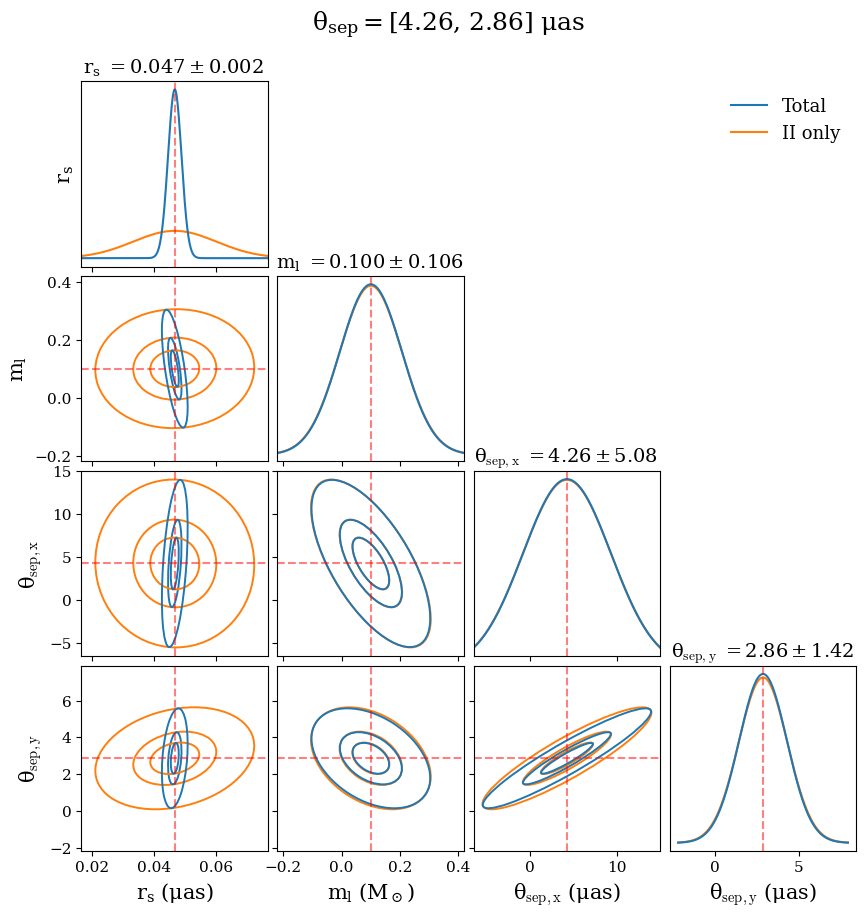

In [58]:
idx=32
pos_x_corner=(position_01[idx][0]-4000)*theta_step
pos_y_corner=(position_01[idx][1]-4000)*theta_step
mass_01_combo[idx]

titles = [r"$r_s\ (mas)$", r"$m_l\ (M_\odot)$",
          r"$\theta_{\rm sep,x}\ (mas)$", r"$\theta_{\rm sep,y}\ (mas)$"]

varlabels = [r"$r_s$", r"$m_l$", r"$\theta_{\rm sep,x}$", r"$\theta_{\rm sep,y}$"]
units = [r"$\mu as$", r"$M_\odot$", r"$\mu as$", r"$\mu as$"]
precision = [3, 3, 2, 2]

mean_vec = np.array([rad_mas, 0.1, pos_x_corner * rad_to_arcsec, pos_y_corner * rad_to_arcsec])
scales=[.03, .32, 10.8, 5.05] 
limits = np.array([[mean_vec[0]-scales[0], mean_vec[0]+scales[0]], [mean_vec[1]-scales[1], mean_vec[1]+scales[1]],
                   [mean_vec[2]-scales[2], mean_vec[2]+scales[2]], [mean_vec[3]-scales[3], mean_vec[3]+scales[3]]])

cov1 = cov_combo_01[idx] 
cov2 = cov_01[idx]

ndim = len(varlabels)

fig = plt.figure(figsize=(10, 10))
gs = fig.add_gridspec(ndim, ndim, hspace=0.05, wspace=0.05)

axes = np.empty((ndim, ndim), dtype=object)
percentiles = [0.16, 0.84]
colors = ["C0", "C0", "C0"]  # or different colors/styles
linewidths = [0.8, 0.8]

colors2 = ["C1", "C1", "C1"]

for i in range(ndim):
    for j in range(ndim):

        if i < j:
            axes[i, j] = fig.add_subplot(gs[i, j])
            axes[i, j].axis("off")
            continue

        if i == j:
            axes[i, j] = fig.add_subplot(gs[i, j])
        else:
            axes[i, j] = fig.add_subplot( gs[i, j], sharex=axes[j, j],  sharey=axes[i, i] )

for i in range(ndim):
    for j in range(ndim):
        ax = axes[i,j]
        if i < j:
            continue

        if i == j:
            # 1D marginal
            sigma1 = np.sqrt(cov1[i,i])
            sigma2 = np.sqrt(cov2[i,i])
            x = np.linspace(limits[j][0], limits[j][1], 500)#mean_vec[i]-4*sigma1, mean_vec[i]+4*sigma1, 500)
            ax.plot(x, gaussian_1d(x, mean_vec[i], sigma2), color="C1")
            ax.plot(x, gaussian_1d(x, mean_vec[i], sigma1), color="C0")
            ax.set_yticks([])
            ax.tick_params(left=False)
            nd = precision[i]
            ax.set_title(fr"{varlabels[i]} $= {mean_vec[i]:.{nd}f} \pm {sigma1:.{nd}f}$ ",
                         fontsize=14)
            ax.axvline(mean_vec[[j,i]][1], color='r', linestyle='dashed', alpha=.5)
        else:
            # 2D ellipse
            mean_ij = mean_vec[[j,i]]
            cov1_ij = cov1[np.ix_([j,i],[j,i])]
            cov2_ij = cov2[np.ix_([j,i],[j,i])]
            ax.set_xlim(limits[j][0], limits[j][1])#mean_vec[j]-4*np.sqrt(cov1[j,j]),
                       # mean_vec[j]+4*np.sqrt(cov1[j,j]))
            ax.set_ylim(limits[i][0], limits[i][1])
                        #mean_vec[i]+4*np.sqrt(cov1[i,i]))
            ax.axvline(mean_ij[0], color='r', linestyle='dashed', alpha=.5)
            ax.axhline(mean_ij[1], color='r', linestyle='dashed', alpha=.5)
            plot_cov_ellipse(mean_ij, cov2_ij, ax, n_sigma=1, edgecolor="C1", linewidth=1.4)
            plot_cov_ellipse(mean_ij, cov1_ij, ax, n_sigma=1, edgecolor="C0", linewidth=1.4)

            for p, c, lw in zip(percentiles, colors2, linewidths):
                n_sigma = np.sqrt(scipy.stats.chi2.ppf(p, df=2))  # df=2 for 2D
                plot_cov_ellipse(mean_ij, cov2_ij, ax, n_sigma=n_sigma,
                                 edgecolor=c, linewidth=1.4)
            for p, c, lw in zip(percentiles, colors, linewidths):
                n_sigma = np.sqrt(scipy.stats.chi2.ppf(p, df=2))  # df=2 for 2D
                plot_cov_ellipse(mean_ij, cov1_ij, ax, n_sigma=n_sigma,
                                 edgecolor=c, linewidth=1.4)

        ax.tick_params(labelsize=11)
            
for i in range(ndim):
    for j in range(ndim):
        ax = axes[i, j]
        if i != ndim - 1:
            ax.tick_params(labelbottom=False)
        if j != 0:
            ax.tick_params(labelleft=False)
        #if i!=j+1:
        ax.set_xlabel(f"{varlabels[j]} ({units[j]})", fontsize=15)
        if i>-1 and j==0:
            ax.set_ylabel(f"{varlabels[i]}", fontsize=15)
        
axes[0, -1].plot([], [], color="C0", label="Total")
axes[0, -1].plot([], [], color="C1", label="II only")
axes[0, -1].legend(frameon=False, fontsize=13)

title=r'$\theta_{{sep}} = [$' + str(format(pos_x_corner*rad_to_arcsec, '.2f')) + ', ' + str(format(pos_y_corner*rad_to_arcsec, '.2f')) + r'$]\ \mu$as'
plt.text(-24, 1.35, title, fontsize=18);
#plt.text(-25, 1.45, r'$\theta_{{sep}} = [-0.31,  0.57]\ \mu$as', fontsize=18);
#plt.show()

plt.savefig('../Figures/corner01_ell.pdf', bbox_inches='tight')
#FileLink('../Figures/corner01_res.pdf')

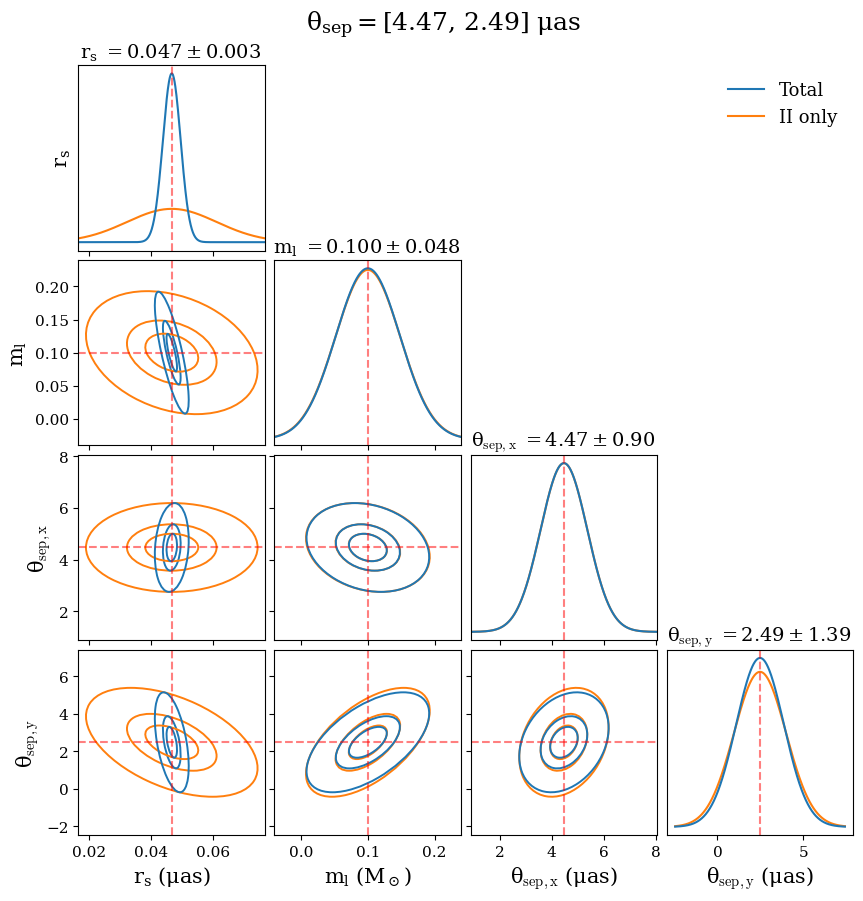

In [23]:
idx=12
pos_x_corner=(position_01[idx][0]-4000)*theta_step
pos_y_corner=(position_01[idx][1]-4000)*theta_step
mass_01_combo[idx]

titles = [r"$r_s\ (mas)$", r"$m_l\ (M_\odot)$",
          r"$\theta_{\rm sep,x}\ (mas)$", r"$\theta_{\rm sep,y}\ (mas)$"]

varlabels = [r"$r_s$", r"$m_l$", r"$\theta_{\rm sep,x}$", r"$\theta_{\rm sep,y}$"]
units = [r"$\mu as$", r"$M_\odot$", r"$\mu as$", r"$\mu as$"]
precision = [3, 3, 2, 2]

mean_vec = np.array([rad_mas, 0.1, pos_x_corner * rad_to_arcsec, pos_y_corner * rad_to_arcsec])
scales=[.03, .14, 3.6, 4.95] 
limits = np.array([[mean_vec[0]-scales[0], mean_vec[0]+scales[0]], [mean_vec[1]-scales[1], mean_vec[1]+scales[1]],
                   [mean_vec[2]-scales[2], mean_vec[2]+scales[2]], [mean_vec[3]-scales[3], mean_vec[3]+scales[3]]])

cov1 = cov_combo_01[idx] 
cov2 = cov_01[idx]

ndim = len(varlabels)

fig = plt.figure(figsize=(10, 10))
gs = fig.add_gridspec(ndim, ndim, hspace=0.05, wspace=0.05)

axes = np.empty((ndim, ndim), dtype=object)
percentiles = [0.16, 0.84]
colors = ["C0", "C0", "C0"]  # or different colors/styles
linewidths = [0.8, 0.8]

colors2 = ["C1", "C1", "C1"]

for i in range(ndim):
    for j in range(ndim):

        if i < j:
            axes[i, j] = fig.add_subplot(gs[i, j])
            axes[i, j].axis("off")
            continue

        if i == j:
            axes[i, j] = fig.add_subplot(gs[i, j])
        else:
            axes[i, j] = fig.add_subplot( gs[i, j], sharex=axes[j, j],  sharey=axes[i, i] )

for i in range(ndim):
    for j in range(ndim):
        ax = axes[i,j]
        if i < j:
            continue

        if i == j:
            # 1D marginal
            sigma1 = np.sqrt(cov1[i,i])
            sigma2 = np.sqrt(cov2[i,i])
            x = np.linspace(limits[j][0], limits[j][1], 500)#mean_vec[i]-4*sigma1, mean_vec[i]+4*sigma1, 500)
            ax.plot(x, gaussian_1d(x, mean_vec[i], sigma2), color="C1")
            ax.plot(x, gaussian_1d(x, mean_vec[i], sigma1), color="C0")
            ax.set_yticks([])
            ax.tick_params(left=False)
            nd = precision[i]
            ax.set_title(fr"{varlabels[i]} $= {mean_vec[i]:.{nd}f} \pm {sigma1:.{nd}f}$ ",
                         fontsize=14)
            ax.axvline(mean_vec[[j,i]][1], color='r', linestyle='dashed', alpha=.5)
        else:
            # 2D ellipse
            mean_ij = mean_vec[[j,i]]
            cov1_ij = cov1[np.ix_([j,i],[j,i])]
            cov2_ij = cov2[np.ix_([j,i],[j,i])]
            ax.set_xlim(limits[j][0], limits[j][1])#mean_vec[j]-4*np.sqrt(cov1[j,j]),
                       # mean_vec[j]+4*np.sqrt(cov1[j,j]))
            ax.set_ylim(limits[i][0], limits[i][1])
                        #mean_vec[i]+4*np.sqrt(cov1[i,i]))
            ax.axvline(mean_ij[0], color='r', linestyle='dashed', alpha=.5)
            ax.axhline(mean_ij[1], color='r', linestyle='dashed', alpha=.5)
            plot_cov_ellipse(mean_ij, cov2_ij, ax, n_sigma=1, edgecolor="C1", linewidth=1.4)
            plot_cov_ellipse(mean_ij, cov1_ij, ax, n_sigma=1, edgecolor="C0", linewidth=1.4)

            for p, c, lw in zip(percentiles, colors2, linewidths):
                n_sigma = np.sqrt(scipy.stats.chi2.ppf(p, df=2))  # df=2 for 2D
                plot_cov_ellipse(mean_ij, cov2_ij, ax, n_sigma=n_sigma,
                                 edgecolor=c, linewidth=1.4)
            for p, c, lw in zip(percentiles, colors, linewidths):
                n_sigma = np.sqrt(scipy.stats.chi2.ppf(p, df=2))  # df=2 for 2D
                plot_cov_ellipse(mean_ij, cov1_ij, ax, n_sigma=n_sigma,
                                 edgecolor=c, linewidth=1.4)

        ax.tick_params(labelsize=11)
            
for i in range(ndim):
    for j in range(ndim):
        ax = axes[i, j]
        if i != ndim - 1:
            ax.tick_params(labelbottom=False)
        if j != 0:
            ax.tick_params(labelleft=False)
        #if i!=j+1:
        ax.set_xlabel(f"{varlabels[j]} ({units[j]})", fontsize=15)
        if i>-1 and j==0:
            ax.set_ylabel(f"{varlabels[i]}", fontsize=15)
        
axes[0, -1].plot([], [], color="C0", label="Total")
axes[0, -1].plot([], [], color="C1", label="II only")
axes[0, -1].legend(frameon=False, fontsize=13)

title=r'$\theta_{{sep}} = [$' + str(format(pos_x_corner*rad_to_arcsec, '.2f')) + ', ' + str(format(pos_y_corner*rad_to_arcsec, '.2f')) + r'$]\ \mu$as'
plt.text(-24, 1.35, title, fontsize=18);
#plt.text(-25, 1.45, r'$\theta_{{sep}} = [-0.31,  0.57]\ \mu$as', fontsize=18);
#plt.show()

plt.savefig('../Figures/corner01_res.pdf', bbox_inches='tight')
#FileLink('../Figures/corner01_res.pdf')

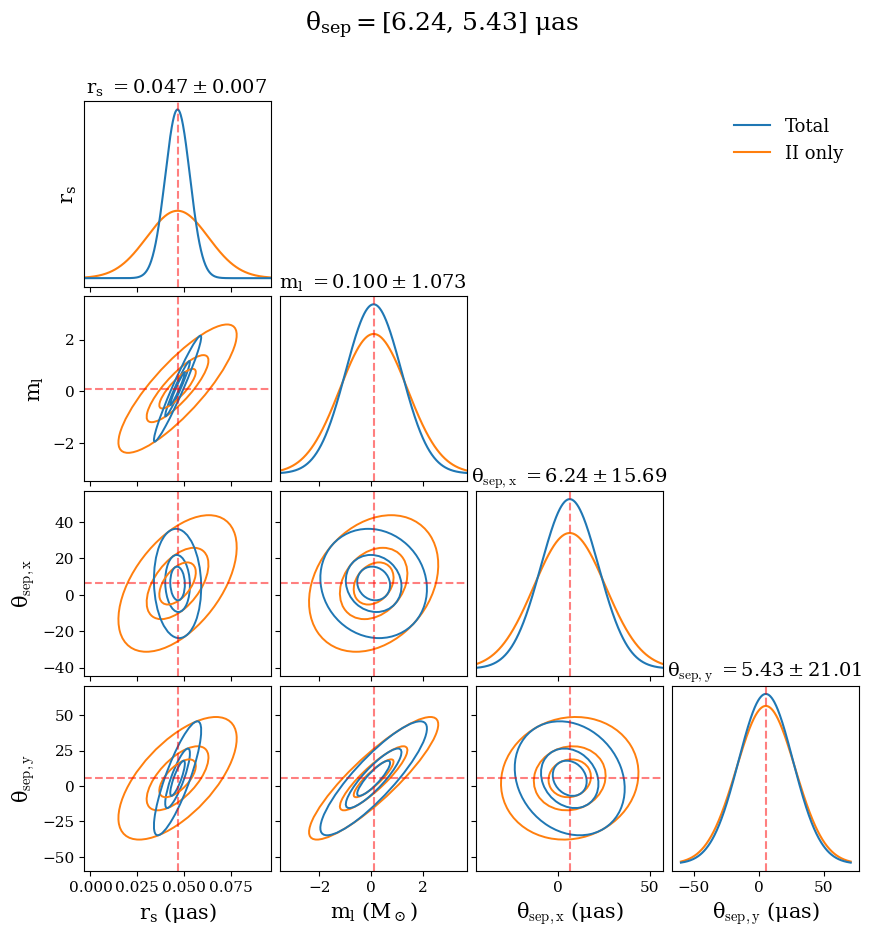

In [40]:
idx=99
pos_x_corner=(position_01[idx][0]-4000)*theta_step
pos_y_corner=(position_01[idx][1]-4000)*theta_step
mass_01_combo[idx]

titles = [r"$r_s\ (mas)$", r"$m_l\ (M_\odot)$",
          r"$\theta_{\rm sep,x}\ (mas)$", r"$\theta_{\rm sep,y}\ (mas)$"]

varlabels = [r"$r_s$", r"$m_l$", r"$\theta_{\rm sep,x}$", r"$\theta_{\rm sep,y}$"]
units = [r"$\mu as$", r"$M_\odot$", r"$\mu as$", r"$\mu as$"]
precision = [3, 3, 2, 2]

mean_vec = np.array([rad_mas, 0.1, pos_x_corner * rad_to_arcsec, pos_y_corner * rad_to_arcsec])
scales=[.05, 3.6, 51, 65.5] 
limits = np.array([[mean_vec[0]-scales[0], mean_vec[0]+scales[0]], [mean_vec[1]-scales[1], mean_vec[1]+scales[1]],
                   [mean_vec[2]-scales[2], mean_vec[2]+scales[2]], [mean_vec[3]-scales[3], mean_vec[3]+scales[3]]])

cov1 = cov_combo_01[idx] 
cov2 = cov_01[idx]

ndim = len(varlabels)

fig = plt.figure(figsize=(10, 10))
gs = fig.add_gridspec(ndim, ndim, hspace=0.05, wspace=0.05)

axes = np.empty((ndim, ndim), dtype=object)
percentiles = [0.16, 0.84]
colors = ["C0", "C0", "C0"]  # or different colors/styles
linewidths = [0.8, 0.8]

colors2 = ["C1", "C1", "C1"]

for i in range(ndim):
    for j in range(ndim):

        if i < j:
            axes[i, j] = fig.add_subplot(gs[i, j])
            axes[i, j].axis("off")
            continue

        if i == j:
            axes[i, j] = fig.add_subplot(gs[i, j])
        else:
            axes[i, j] = fig.add_subplot( gs[i, j], sharex=axes[j, j],  sharey=axes[i, i] )

for i in range(ndim):
    for j in range(ndim):
        ax = axes[i,j]
        if i < j:
            continue

        if i == j:
            # 1D marginal
            sigma1 = np.sqrt(cov1[i,i])
            sigma2 = np.sqrt(cov2[i,i])
            x = np.linspace(limits[j][0], limits[j][1], 500)#mean_vec[i]-4*sigma1, mean_vec[i]+4*sigma1, 500)
            ax.plot(x, gaussian_1d(x, mean_vec[i], sigma2), color="C1")
            ax.plot(x, gaussian_1d(x, mean_vec[i], sigma1), color="C0")
            ax.set_yticks([])
            ax.tick_params(left=False)
            nd = precision[i]
            ax.set_title(fr"{varlabels[i]} $= {mean_vec[i]:.{nd}f} \pm {sigma1:.{nd}f}$ ",
                         fontsize=14)
            ax.axvline(mean_vec[[j,i]][1], color='r', linestyle='dashed', alpha=.5)
        else:
            # 2D ellipse
            mean_ij = mean_vec[[j,i]]
            cov1_ij = cov1[np.ix_([j,i],[j,i])]
            cov2_ij = cov2[np.ix_([j,i],[j,i])]
            ax.set_xlim(limits[j][0], limits[j][1])#mean_vec[j]-4*np.sqrt(cov1[j,j]),
                       # mean_vec[j]+4*np.sqrt(cov1[j,j]))
            ax.set_ylim(limits[i][0], limits[i][1])
                        #mean_vec[i]+4*np.sqrt(cov1[i,i]))
            ax.axvline(mean_ij[0], color='r', linestyle='dashed', alpha=.5)
            ax.axhline(mean_ij[1], color='r', linestyle='dashed', alpha=.5)
            plot_cov_ellipse(mean_ij, cov2_ij, ax, n_sigma=1, edgecolor="C1", linewidth=1.4)
            plot_cov_ellipse(mean_ij, cov1_ij, ax, n_sigma=1, edgecolor="C0", linewidth=1.4)

            for p, c, lw in zip(percentiles, colors2, linewidths):
                n_sigma = np.sqrt(scipy.stats.chi2.ppf(p, df=2))  # df=2 for 2D
                plot_cov_ellipse(mean_ij, cov2_ij, ax, n_sigma=n_sigma,
                                 edgecolor=c, linewidth=1.4)
            for p, c, lw in zip(percentiles, colors, linewidths):
                n_sigma = np.sqrt(scipy.stats.chi2.ppf(p, df=2))  # df=2 for 2D
                plot_cov_ellipse(mean_ij, cov1_ij, ax, n_sigma=n_sigma,
                                 edgecolor=c, linewidth=1.4)

        ax.tick_params(labelsize=11)
            
for i in range(ndim):
    for j in range(ndim):
        ax = axes[i, j]
        if i != ndim - 1:
            ax.tick_params(labelbottom=False)
        if j != 0:
            ax.tick_params(labelleft=False)
        #if i!=j+1:
        ax.set_xlabel(f"{varlabels[j]} ({units[j]})", fontsize=15)
        if i>-1 and j==0:
            ax.set_ylabel(f"{varlabels[i]}", fontsize=15)
        
axes[0, -1].plot([], [], color="C0", label="Total")
axes[0, -1].plot([], [], color="C1", label="II only")
axes[0, -1].legend(frameon=False, fontsize=13)

title=r'$\theta_{{sep}} = [$' + str(format(pos_x_corner*rad_to_arcsec, '.2f')) + ', ' + str(format(pos_y_corner*rad_to_arcsec, '.2f')) + r'$]\ \mu$as'
plt.text(-350, .093, title, fontsize=18);
#plt.show()

plt.savefig('../Figures/corner01_unres.pdf', bbox_inches='tight')
#FileLink('../Figures/corner01_unres.pdf')

### Interpolate errors

In [24]:
n = int(np.sqrt(len(x_rot)))

# build grid of points rotated by phi_0
x_grid = np.unique(positions_rot[:, 0].round(decimals=18))#*theta_step * image_size
x_grid = np.concat((x_grid, (-x_grid[len(x_grid)-2::-1])))
y_grid = np.unique(positions_rot[:, 1].round(decimals=15))#*theta_step * image_size
y_grid = np.concat((-y_grid[::-1], (y_grid[1:])))

rad_grid  = rad_01_combo.reshape(n, n)
mass_grid = mass_01_combo.reshape(n, n)
xpos_grid = posx_01_combo.reshape(n, n)
ypos_grid = posy_01_combo.reshape(n, n)


In [25]:
rad_grid  = one_quad_to_full(rad_01_combo, n)
mass_grid = one_quad_to_full(mass_01_combo, n)
xpos_grid = one_quad_to_full(posx_01_combo, n)
ypos_grid = one_quad_to_full(posy_01_combo, n)


In [26]:
# Build interpolators
rad_spline  = RegularGridInterpolator([x_grid, y_grid], rad_grid, method='linear')
mass_spline = RegularGridInterpolator([x_grid, y_grid], mass_grid, method='linear')
xpos_spline = RegularGridInterpolator([x_grid, y_grid], xpos_grid, method='linear') #takes position in radians, returns in mas
ypos_spline = RegularGridInterpolator([x_grid, y_grid], ypos_grid, method='linear')

In [27]:
# build fine grid to test these functions
fine_grid_x=np.linspace(np.min(x_grid), np.max(x_grid), 200)
fine_grid_y=np.linspace(np.min(y_grid), np.max(y_grid), 200)
X_fine, Y_fine = np.meshgrid(fine_grid_x, fine_grid_y, indexing='ij')


In [28]:
#evlulate on the dense grids for plotting
points = np.stack([X_fine.ravel(), Y_fine.ravel()], axis=-1)
rad_interp = rad_spline(points).reshape(X_fine.shape)
mass_interp = mass_spline(points).reshape(X_fine.shape)
xpos_interp = xpos_spline(points).reshape(X_fine.shape)
ypos_interp = ypos_spline(points).reshape(X_fine.shape)

### Interpolate fisher matricies for m=0.1

In [29]:
# do this element wise, reshape back to a 4x4 grid at each point in the n x n grid
f_combo_01=[]
for i in range(len(cov_combo_01)):
    f_combo_01.append(np.linalg.inv(cov_combo_01[i]))
f_combo_01=np.array(f_combo_01)
f_combo_01 = f_combo_01.reshape(n, n, 4, 4)
f_combo_01  = matrix_to_full(f_combo_01, n)

In [30]:
#interpolate each element of the fisher matricies separately
interpolators = [[None for j in range(4)] for i in range(4)]

for i in range(4):
    for j in range(4):
        # Linear interpolation; 'bounds_error=False' allows extrapolation if needed
        interpolators[i][j] = RegularGridInterpolator(
            (x_grid, y_grid),
            f_combo_01[:, :, i, j], bounds_error=False, method='linear', fill_value=np.nan)
#build the function which will call each interpolator and put into a matrix
def fisher_interp_linear(pos):
    x, y = pos
    M = np.zeros((4, 4))
    for i in range(4):
        for j in range(4):
            M[i, j] = interpolators[i][j]([x, y])
    # enforce symmetry
    M = 0.5 * (M + M.T)
    return M

### Interpolate chi^2, J_cent

Same process as above, interpolate everything element wise if necessary, and build into a function. 

In [31]:
chi_grid  = one_quad_to_full(chi_combo_01, n)

fine_grid_x=np.linspace(np.min(x_grid), np.max(x_grid), 200)
fine_grid_y=np.linspace(np.min(y_grid), np.max(y_grid), 200)
X_fine, Y_fine = np.meshgrid(fine_grid_x, fine_grid_y, indexing='ij')
points = np.stack([X_fine.ravel(), Y_fine.ravel()], axis=-1)

chi_spline  = RegularGridInterpolator([x_grid, y_grid], chi_grid, bounds_error=False, method='linear', fill_value=np.nan)
chi_interp  = chi_spline(points).reshape(X_fine.shape)

In [32]:
chi_grid_II  = one_quad_to_full(chis_01_II, n)
chi_spline_II  = RegularGridInterpolator([x_grid, y_grid], chi_grid_II, bounds_error=False, method='linear', fill_value=np.nan)

chi_grid_mag  = one_quad_to_full(chis_01_mag, n)
chi_spline_mag  = RegularGridInterpolator([x_grid, y_grid], chi_grid_mag, bounds_error=False, method='linear', fill_value=np.nan)

In [ ]:

centroids=centroids.reshape(n,n,2,4)
Jcent_grid  = Jac_to_full(centroids, n)

interpolators_cent=[[None for i in range(4)] for a in range(2)]

for a in range(2):        # centroid x/y
    for i in range(4):    # parameters
        interpolators_cent[a][i] = RegularGridInterpolator(
        (x_grid, y_grid),
        Jcent_grid[:, :, a, i], bounds_error=False, method='linear', fill_value=np.nan)

def Jcent_interp(pos):
    x, y = pos
    J = np.zeros((2, 4))
    for a in range(2):
        for i in range(4):
            J[a, i] = interpolators_cent[a][i]([x, y])
    return J

cent_pres  = one_quad_to_full(cent_pres, n)
cent_spline = RegularGridInterpolator([x_grid, y_grid], cent_pres, method='linear', fill_value=np.nan)
cent_interp = cent_spline(points).reshape(X_fine.shape)

sigma_c1  = one_quad_to_full(sigma_c1, n)
sigma_c1_spline = RegularGridInterpolator([x_grid, y_grid], sigma_c1, method='linear', fill_value=np.nan)
sigma_c1_interp = sigma_c1_spline(points).reshape(X_fine.shape)

sigma_c2  = one_quad_to_full(sigma_c2, n)
sigma_c2_spline = RegularGridInterpolator([x_grid, y_grid], sigma_c2, method='linear', fill_value=np.nan)
sigma_c2_interp = sigma_c2_spline(points).reshape(X_fine.shape)



ValueError: cannot reshape array of size 1521 into shape (20,20)

In [39]:
sigma_c1_res  = one_quad_to_full(sigma_c1_res, n)
sigma_c1res_spline = RegularGridInterpolator([x_grid, y_grid], sigma_c1_res, method='linear', fill_value=np.nan)
sigma_c1res_interp = sigma_c1res_spline(points).reshape(X_fine.shape)

sigma_c2_res  = one_quad_to_full(sigma_c2_res, n)
sigma_c2res_spline = RegularGridInterpolator([x_grid, y_grid], sigma_c2_res, method='linear', fill_value=np.nan)
sigma_c2res_interp = sigma_c2res_spline(points).reshape(X_fine.shape)


In [38]:
sigma_c1_res.shape

(400,)

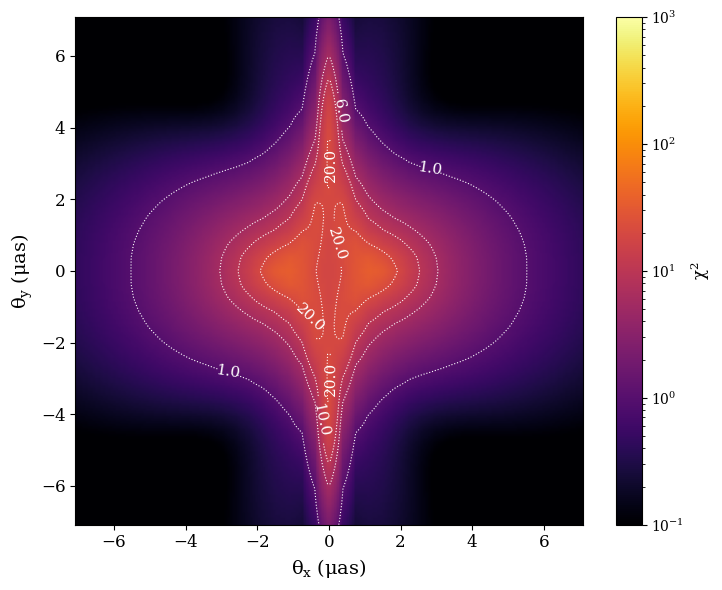

In [34]:
Z = np.flipud(chi_interp).T
X, Y = np.meshgrid(fine_grid_x*rad_to_arcsec, fine_grid_y*rad_to_arcsec)
extent = np.array([np.min(fine_grid_x), np.max(fine_grid_x),  np.min(fine_grid_y), np.max(fine_grid_y)])*rad_to_arcsec    

levels=[1, 6, 10, 20]
fig, ax = plt.subplots(figsize=(12, 6))

im = ax.imshow(Z, origin='lower', extent=extent, cmap='inferno', norm=matplotlib.colors.LogNorm(vmin=.1,vmax=1000),)
contours = ax.contour(X, Y, Z, levels=levels, colors='white', linewidths=0.8, linestyles='dotted')
ax.clabel(contours, inline=True, fontsize=11, fmt="%.1f")

cbar = plt.colorbar(im, ax=ax, fraction=0.045, pad=.03)
cbar.set_label(r'$\chi^2$', fontsize=12)

ax.tick_params(axis='both', which='major', labelsize=12)
ax.tick_params(axis='both', which='minor', labelsize=10)

ax.set_xlabel(r'$\theta_x \ (\mu as)$', fontsize=14)
ax.set_ylabel(r'$\theta_y \ (\mu as)$', fontsize=14)
plt.tight_layout()
#plt.savefig('../Figures/chi01.pdf', bbox_inches='tight')
#FileLink('../Figures/chi01.pdf')

### Error Plots

Plots of the interpolated errors as evaluted on a finer grid of points

We see some numerical noise but within what we would expect to see

In [35]:
orig_map=plt.cm.get_cmap('cividis')

# reversing the original colormap using reversed() function
reversed_map = orig_map.reversed()

/tmp/ipykernel_100153/603653901.py:1: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  orig_map=plt.cm.get_cmap('cividis')


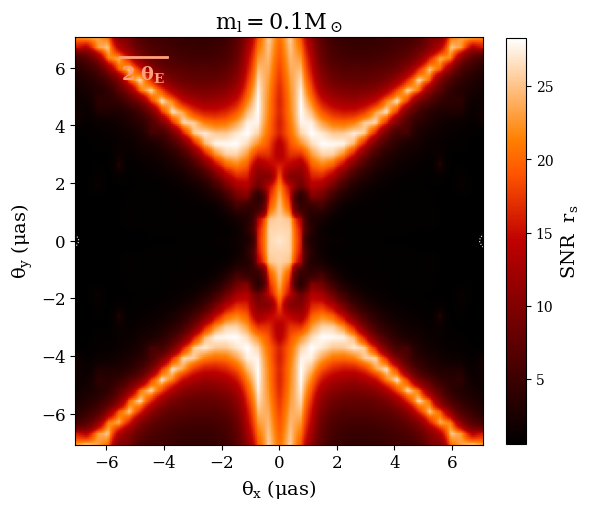

In [21]:
fig, (ax1) = plt.subplots(nrows=1, ncols=1, figsize=(6, 8))
extent = np.array([np.min(fine_grid_x), np.max(fine_grid_x),  np.min(fine_grid_y), np.max(fine_grid_y)])*rad_to_arcsec    
extent2 = [-theta_max, theta_max, -theta_max, theta_max]    #left right bottom top 

X, Y = np.meshgrid(fine_grid_x*rad_to_arcsec, fine_grid_y*rad_to_arcsec)
Z = rad_mas/np.flipud(rad_interp).T

levels=[.1, .6]
im=ax1.imshow(Z, origin='lower', extent=extent, cmap='gist_heat')
cbar = plt.colorbar(im, ax=ax1, fraction=0.045)
cbar.set_label(r'SNR $ \ r_s$', fontsize=14)

#contours
contours = ax1.contour(X, Y, Z, levels=levels, colors='white', linewidths=0.8, linestyles='dotted')
ax1.clabel(contours, inline=True, fontsize=10, fmt="%.1f")

#scale thing
scale_length = 2*theta_E_1*rad_to_arcsec    

# pick a position for the bar 
x_start = np.min(fine_grid_x) - 3.4 * scale_length
x_end = x_start + scale_length
y_pos = np.max(fine_grid_y*rad_to_arcsec)  + .1 *np.min(fine_grid_y*rad_to_arcsec)
ax1.plot([x_start, x_end], [y_pos, y_pos], color='lightsalmon', lw=2)
ax1.text((x_start + x_end) / 2, y_pos * .85, r"$ 2 \ \theta_{E}$", color='lightsalmon', ha='center', va='bottom', fontsize=14,
         fontweight='black')#, backgroundcolor='white')


ax1.tick_params(axis='both', which='major', labelsize=12)
ax1.tick_params(axis='both', which='minor', labelsize=10)
plt.title(r'$m_l=0.1M_\odot$', fontsize=16)
#ax1.set_xlim(-1.4e-11, .1e-11)
#ax1.set_ylim(-.1e-11, 1.4e-11)


ax1.set_xlabel(r'$\theta_x \ (\mu as)$', fontsize=14)
ax1.set_ylabel(r'$\theta_y \ (\mu as)$', fontsize=14)
plt.tight_layout()

plt.savefig('../Figures/chi01.pdf', bbox_inches='tight')
#FileLink('../Figures/chi01.pdf')

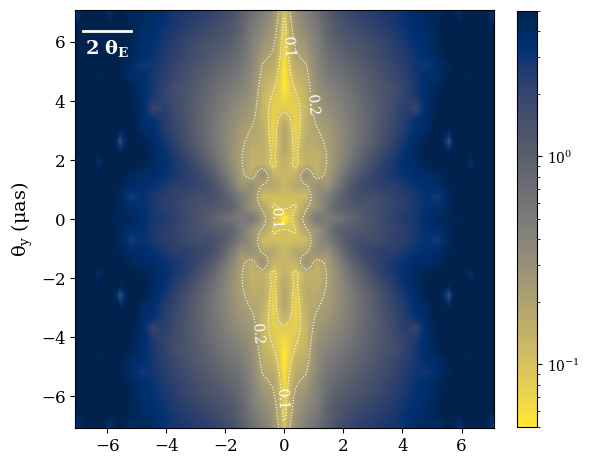

In [24]:
fig, (ax1) = plt.subplots(nrows=1, ncols=1, figsize=(6, 8))
extent = np.array([np.min(fine_grid_x), np.max(fine_grid_x),  np.min(fine_grid_y), np.max(fine_grid_y)])*rad_to_arcsec    
extent2 = [-theta_max, theta_max, -theta_max, theta_max]    #left right bottom top 

X, Y = np.meshgrid(fine_grid_x*rad_to_arcsec, fine_grid_y*rad_to_arcsec)
Z = np.flipud(mass_interp).T

levels=[ .1, .2]
im=ax1.imshow(np.flipud(mass_interp).T, origin='lower', cmap=reversed_map, norm=matplotlib.colors.LogNorm(vmin=.05,vmax=5), extent=extent)
cbar = plt.colorbar(im, ax=ax1, fraction=0.045)
#cbar.set_label(r'$ \sigma \ [m_l]\  (M_\odot)$', fontsize=14)

#contours
contours = ax1.contour(X, Y, Z, levels=levels, colors='white', linewidths=0.8, linestyles='dotted')
ax1.clabel(contours, inline=True, fontsize=10, fmt="%.1f")

scale_length = 2*theta_E_1*rad_to_arcsec    

# pick a position for the bar 
x_start = np.min(fine_grid_x) - 4.2 * scale_length
x_end = x_start + scale_length
y_pos = np.max(fine_grid_y*rad_to_arcsec)  + .1 *np.min(fine_grid_y*rad_to_arcsec)
ax1.plot([x_start, x_end], [y_pos, y_pos], color='white', lw=2)
ax1.text((x_start + x_end) / 2, y_pos * .85, r"$ 2 \ \theta_{E}$", color='white', ha='center', va='bottom', fontsize=14,
         fontweight='black')#, backgroundcolor='white')

ax1.tick_params(axis='both', which='major', labelsize=12)
ax1.tick_params(axis='both', which='minor', labelsize=10)
#plt.title(r'$m_l=0.8M_\odot$', fontsize=16)
#ax1.set_xlim(-1.4e-11, .1e-11)
#ax1.set_ylim(-.1e-11, 1.4e-11)


#ax1.set_xlabel(r'$\theta_x \ (\mu as)$', fontsize=14)
ax1.set_ylabel(r'$\theta_y \ (\mu as)$', fontsize=14)
plt.tight_layout()


plt.savefig('../Figures/mass_01.pdf', bbox_inches='tight')
#FileLink('../Figures/mass_01.pdf')

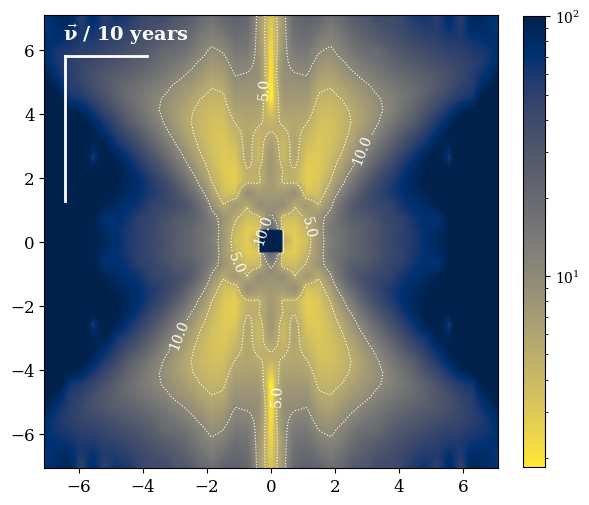

In [26]:
fig, (ax1) = plt.subplots(nrows=1, ncols=1, figsize=(6, 8))
extent = np.array([np.min(fine_grid_x), np.max(fine_grid_x),  np.min(fine_grid_y), np.max(fine_grid_y)])*rad_to_arcsec    

X, Y = np.meshgrid(fine_grid_x*rad_to_arcsec, fine_grid_y*rad_to_arcsec)
Z = np.sqrt(np.flipud(xpos_interp).T**2+np.flipud(xpos_interp).T**2)
levels=[5, 10]
im=ax1.imshow(Z, origin='lower',cmap=reversed_map,norm=matplotlib.colors.LogNorm(vmax=100), extent=extent)
cbar = plt.colorbar(im, ax=ax1, fraction=0.045)
#cbar.set_label(r'$ \sigma \ [\theta_{\text{sep}}] \ (\mu as)$', fontsize=14)

#contours
contours = ax1.contour(X, Y, Z, levels=levels, colors='white', linewidths=0.8, linestyles='dotted')
ax1.clabel(contours, inline=True, fontsize=10, fmt="%.1f")

scale_length_x=mu_x*10
x_start = np.min(fine_grid_x) - 2.5 * scale_length_x
x_end = x_start + scale_length_x
y_pos = np.max(fine_grid_y*rad_to_arcsec)  + .18 *np.min(fine_grid_y*rad_to_arcsec)
ax1.plot([x_start, x_end], [y_pos, y_pos], color='white', lw=2)
ax1.text(x_start+1.9, y_pos * 1.05, r"$\vec{\nu} \ / $ 10 years", color='white', ha='center', va='bottom', fontsize=14,
         fontweight='black')#, backgroundcolor='white') # this is lensed along the x axis!!

scale_length_y=mu_y*10
y_start = y_pos-scale_length_y #np.max(fine_grid_y) + .2 * scale_length_y
y_end = y_start + scale_length_y
x_pos = x_start#-np.max(fine_grid_x*rad_to_arcsec)  +.1 *np.min(fine_grid_x*rad_to_arcsec)
ax1.plot([x_pos, x_pos], [y_start, y_end], color='white', lw=2)
#ax1.text(x_start+1.9, y_pos * .83, r"$\nu \ / $ 10 years", color='white', ha='center', va='bottom', fontsize=14,
#         fontweight='black')#, backgroundcolor='white') # this is lensed along the x axis!!

ax1.tick_params(axis='both', which='major', labelsize=12)
ax1.tick_params(axis='both', which='minor', labelsize=10)

#ax1.set_xlabel(r'$\theta_x \ (\mu as)$', fontsize=14)
#ax1.set_ylabel(r'$\theta_y \ (\mu as)$', fontsize=14)
plt.tight_layout()

plt.savefig('../Figures/pos_01.pdf', bbox_inches='tight')
#FileLink('../Figures/pos_01.pdf')

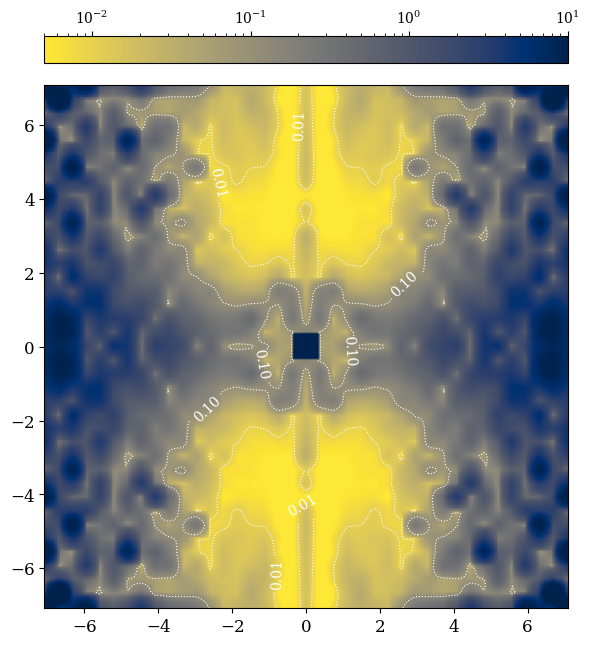

In [23]:
fig, (ax1) = plt.subplots(nrows=1, ncols=1, figsize=(6, 8))
extent = np.array([np.min(fine_grid_x), np.max(fine_grid_x),  np.min(fine_grid_y), np.max(fine_grid_y)])*rad_to_arcsec    

X, Y = np.meshgrid(fine_grid_x*rad_to_arcsec, fine_grid_y*rad_to_arcsec)
Z = np.flipud(sigma_c2_interp).T
levels=[.01, .1]#2, 5, 10]
im=ax1.imshow(Z, origin='lower', cmap=reversed_map, extent=extent, norm=matplotlib.colors.LogNorm(vmin=5e-3, vmax=1e1))#,  vmax=68, vmin=1)
cbar = plt.colorbar(im, ax=ax1, fraction=0.045, pad=.03, orientation='horizontal', location='top')
#cbar.set_label(r'$ \sigma \ [|\theta_{\text{c}}|] \ (\mu as)$', fontsize=14)

#contours
contours = ax1.contour(X, Y, Z, levels=levels, colors='white', linewidths=0.8, linestyles='dotted')
ax1.clabel(contours, inline=True, fontsize=10, fmt="%.2f")

ax1.tick_params(axis='both', which='major', labelsize=12)
ax1.tick_params(axis='both', which='minor', labelsize=10)
#plt.title(r'$m_l=0.8M_\odot$', fontsize=16)
#ax1.set_xlim(-1.4e-11, .1e-11)
#ax1.set_ylim(-.1e-11, 1.4e-11)

#ax1.set_xlabel(r'$\theta_x \ (\mu as)$', fontsize=14)
#ax1.set_ylabel(r'$\theta_y \ (\mu as)$', fontsize=14)
plt.tight_layout()
plt.savefig('../Figures/thetac2_01.pdf', bbox_inches='tight')
#FileLink('../Figures/thetac_01.pdf')

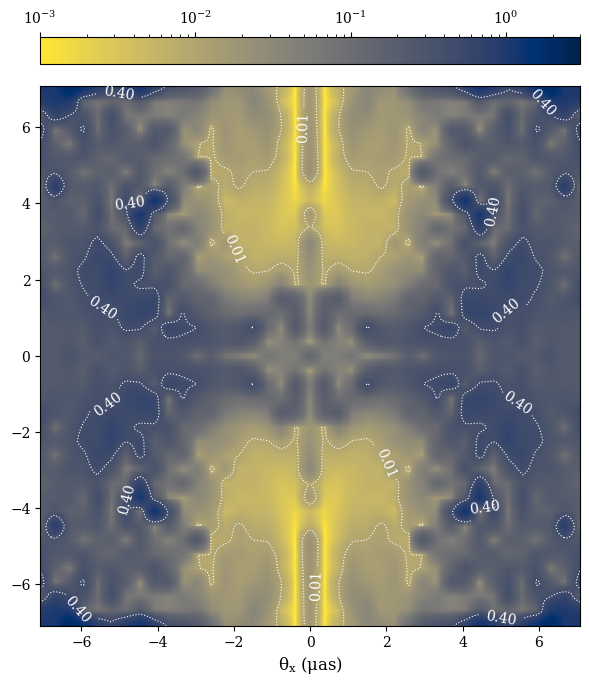

In [54]:
fig, (ax1) = plt.subplots(nrows=1, ncols=1, figsize=(6, 8))
extent = np.array([np.min(fine_grid_x), np.max(fine_grid_x),  np.min(fine_grid_y), np.max(fine_grid_y)])*rad_to_arcsec    

X, Y = np.meshgrid(fine_grid_x*rad_to_arcsec, fine_grid_y*rad_to_arcsec)
Z = np.flipud(sigma_c2res_interp).T
levels=[.01, .4]

im=ax1.imshow(Z, origin='lower', cmap=reversed_map, extent=extent, norm=matplotlib.colors.LogNorm(vmin=1e-3, vmax=3))#,  vmax=68, vmin=1)
cbar = plt.colorbar(im, ax=ax1, fraction=0.045, pad=.03, orientation='horizontal', location='top')
#cbar.set_label(r'$ \Sigma^{\text{res}} \ [|\theta_{\text{c}}|] \ (\mu as)$', fontsize=14)

#contours
contours = ax1.contour(X, Y, Z, levels=levels, colors='white', linewidths=0.8, linestyles='dotted')
ax1.clabel(contours, inline=True, fontsize=10, fmt="%.2f")

ax1.tick_params(axis='both', which='major', labelsize=10)
ax1.tick_params(axis='both', which='minor', labelsize=9)
#plt.title(r'$m_l=0.8M_\odot$', fontsize=16)
#ax1.set_xlim(-1.4e-11, .1e-11)
#ax1.set_ylim(-.1e-11, 1.4e-11)

ax1.set_xlabel(r'$\theta_x \ (\mu as)$', fontsize=12)
#ax1.set_ylabel(r'$\theta_y \ (\mu as)$', fontsize=14)
plt.tight_layout()


plt.savefig('../Figures/thetac2res_01.pdf', bbox_inches='tight')


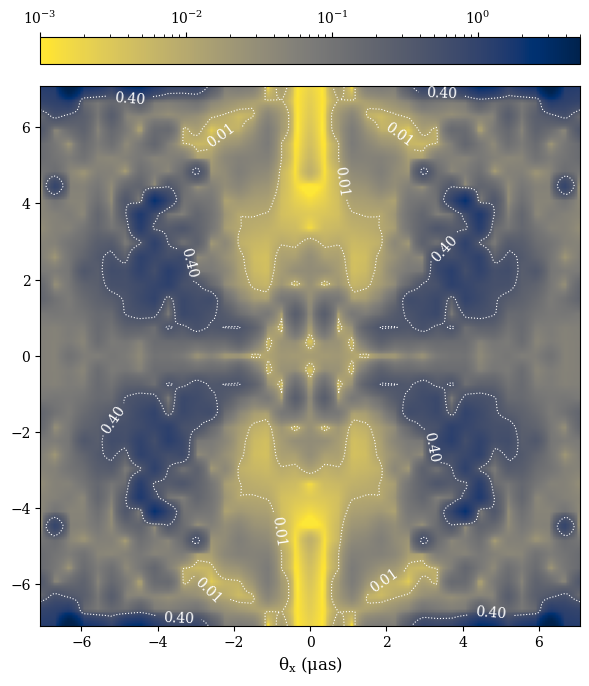

In [52]:
fig, (ax1) = plt.subplots(nrows=1, ncols=1, figsize=(6, 8))
extent = np.array([np.min(fine_grid_x), np.max(fine_grid_x),  np.min(fine_grid_y), np.max(fine_grid_y)])*rad_to_arcsec    

X, Y = np.meshgrid(fine_grid_x*rad_to_arcsec, fine_grid_y*rad_to_arcsec)
Z = np.flipud(sigma_c1res_interp).T
levels=[.01, .4]

im=ax1.imshow(Z, origin='lower', cmap=reversed_map, extent=extent, norm=matplotlib.colors.LogNorm(vmin=1e-3, vmax=5))#,  vmax=68, vmin=1)
cbar = plt.colorbar(im, ax=ax1, fraction=0.045, pad=.03, orientation='horizontal', location='top')
#cbar.set_label(r'$ \Sigma^{\text{res}} \ [|\theta_{\text{c}}|] \ (\mu as)$', fontsize=14)

#contours
contours = ax1.contour(X, Y, Z, levels=levels, colors='white', linewidths=0.8, linestyles='dotted')
ax1.clabel(contours, inline=True, fontsize=10, fmt="%.2f")

ax1.tick_params(axis='both', which='major', labelsize=10)
ax1.tick_params(axis='both', which='minor', labelsize=9)
#plt.title(r'$m_l=0.8M_\odot$', fontsize=16)
#ax1.set_xlim(-1.4e-11, .1e-11)
#ax1.set_ylim(-.1e-11, 1.4e-11)

ax1.set_xlabel(r'$\theta_x \ (\mu as)$', fontsize=12)
#ax1.set_ylabel(r'$\theta_y \ (\mu as)$', fontsize=14)
plt.tight_layout()


plt.savefig('../Figures/thetac1res_01.pdf', bbox_inches='tight')


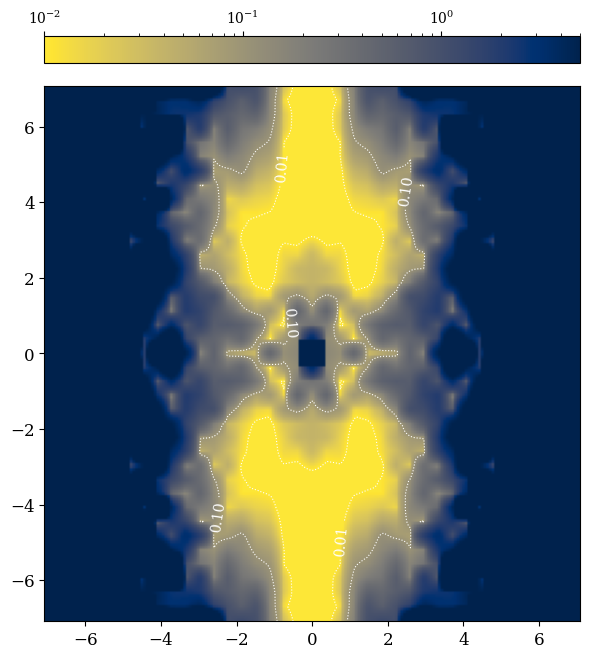

In [50]:
fig, (ax1) = plt.subplots(nrows=1, ncols=1, figsize=(6, 8))
extent = np.array([np.min(fine_grid_x), np.max(fine_grid_x),  np.min(fine_grid_y), np.max(fine_grid_y)])*rad_to_arcsec    

X, Y = np.meshgrid(fine_grid_x*rad_to_arcsec, fine_grid_y*rad_to_arcsec)
Z = np.flipud(sigma_c1_interp).T
levels=[.01, .1]#2, 5, 10]
im=ax1.imshow(Z, origin='lower', cmap=reversed_map, extent=extent, norm=matplotlib.colors.LogNorm(vmin=1e-2, vmax=5))#,  vmax=68, vmin=1)
cbar = plt.colorbar(im, ax=ax1, fraction=0.045, pad=.03, orientation='horizontal', location='top')
#cbar.set_label(r'$ \sigma \ [|\theta_{\text{c}}|] \ (\mu as)$', fontsize=14)

#contours
contours = ax1.contour(X, Y, Z, levels=levels, colors='white', linewidths=0.8, linestyles='dotted')
ax1.clabel(contours, inline=True, fontsize=10, fmt="%.2f")

ax1.tick_params(axis='both', which='major', labelsize=12)
ax1.tick_params(axis='both', which='minor', labelsize=10)
#plt.title(r'$m_l=0.8M_\odot$', fontsize=16)
#ax1.set_xlim(-1.4e-11, .1e-11)
#ax1.set_ylim(-.1e-11, 1.4e-11)

#ax1.set_xlabel(r'$\theta_x \ (\mu as)$', fontsize=14)
#ax1.set_ylabel(r'$\theta_y \ (\mu as)$', fontsize=14)
plt.tight_layout()
plt.savefig('../Figures/thetac1_01.pdf', bbox_inches='tight')
#FileLink('../Figures/thetac_01.pdf')

### Uncertainties as a function of min impact parameter

In [22]:
from II_funcs import *

In [23]:
def centroid_acceleration_uncertainty(centroid_cov_traj, times_days):
    """
    Estimate uncertainty on centroid acceleration by fitting a quadratic
    model c(t) = c0 + v*t + 0.5*a*t^2 to the centroid trajectory.

    Parameters
    ----------
    centroid_cov_traj : array, shape (N, 2, 2)
        Centroid position covariance at each timestep (radians^2)
    times_days : array, shape (N,)
        Observation times in days

    Returns
    -------
    cov_acc : array, shape (2, 2)
        Covariance of centroid acceleration [a_x, a_y] (rad/s^2)^2
    sigma_acc : array, shape (2,)
        1-sigma uncertainty on acceleration in each sky direction
    """
    times_s = times_days * 86400.0
    F = np.zeros((6, 6))

    for i, t in enumerate(times_s):
        # Design matrix: maps [cx0, cy0, vx, vy, ax, ay] -> [cx(t), cy(t)]
        A_i = np.array([[1, 0, t, 0, t**2/2, 0],
            [0, 1, 0, t, 0,t**2/2]])  # shape (2, 6)
        C_inv = np.linalg.inv(centroid_cov_traj[i])
        F += A_i.T @ C_inv @ A_i

    cov_full = np.linalg.inv(F)         # full (6,6) covariance
    cov_acc  = cov_full[4:6, 4:6]      # acceleration block only
    sigma_acc = np.sqrt(np.diag(cov_acc))
    return cov_acc, sigma_acc

def unlens_sigma_from_cov(cov_Theta, B_matrix, redshift, lens_dist_cm):
    """
    Given the 6x6 Theta covariance, return the 1σ uncertainties
    on *unlensed* (physical) vx, vy in km/s.
    """
    cov_mu = cov_Theta[4:6, 4:6]   # 2x2 lensed angular-velocity covariance

    B_inv = np.linalg.inv(B_matrix)
    J = (1 + redshift) * lens_dist_cm * B_inv   # Jacobian

    cov_v_cm = J @ cov_mu @ J.T                 # cm^2/s^2
    cov_v_kms = cov_v_cm / (1e5**2)             # (km/s)^2

    sigma_v_kms = np.sqrt(np.diag(cov_v_kms))   
    return cov_v_cm, cov_v_kms, sigma_v_kms

def average_errors_traj(bulk_vel,bulk_vel_err,vel_disp,vel_disp_err,theta_max,N,redshift,lens_dist,B_matrix,dist,chi_spline,dt_days=182.0,max_time_days=5*365.0,n_its=100,fisher_spline=fisher_interp_linear):

    fisher_thetas=[]
    cov_thetas=[]
    uncert_thetas=[]
    vels=[]
    chi_all=[]
    retries=[]
    Jcents=[]
    acc_covs=[]
    acc_sigmas=[]
    cent_cov_trajs=[]
    pos_trajs=[]
    time_trajs=[]

    for it in range(n_its):

        test_traj=sim_rand_traj(bulk_vel,bulk_vel_err,vel_disp,vel_disp_err,theta_max,N,redshift,lens_dist,B_matrix,dist,dt_days=dt_days,max_time_days=max_time_days)

        positions_traj=test_traj['positions_rad']
        times_traj=test_traj['times_days']

        retry=0

        fisher_alpha=np.array([fisher_spline(p) for p in positions_traj])
        chi_traj=np.array([chi_spline(p) for p in positions_traj])
        centJ_traj=np.array([Jcent_interp(p) for p in positions_traj]).reshape(-1,2,4)

        fisher_theta_traj=f_alpha_to_f_Theta(fisher_alpha,times_traj*(3600*24))
        cov_Theta,uncert_Theta=parameter_uncertainties(fisher_theta_traj,theta_step,printout=False,numstars=1)

        while np.any(np.isnan(uncert_Theta)):

            retry+=1

            test_traj=sim_rand_traj(bulk_vel,bulk_vel_err,vel_disp,vel_disp_err,theta_max,N,redshift,lens_dist,B_matrix,dist,dt_days=dt_days,max_time_days=max_time_days)

            positions_traj=test_traj['positions_rad']
            times_traj=test_traj['times_days']

            fisher_alpha=np.array([fisher_spline(p) for p in positions_traj])
            chi_traj=np.array([chi_spline(p) for p in positions_traj])
            centJ_traj=np.array([Jcent_interp(p) for p in positions_traj]).reshape(-1,2,4)

            fisher_theta_traj=f_alpha_to_f_Theta(fisher_alpha,times_traj*(3600*24))
            cov_Theta,uncert_Theta=parameter_uncertainties(fisher_theta_traj,theta_step,printout=False,numstars=1)

        retries.append(retry)

        pos_trajs.append(positions_traj)
        time_trajs.append(times_traj)
        vels.append(test_traj['velocity_kms'])

        chi_all.append(np.sum(chi_traj))

        C_alpha=np.linalg.inv(fisher_alpha)
        centroid_cov_traj=np.einsum('nij,njk,nlk->nil',centJ_traj,C_alpha,centJ_traj)

        cent_cov_trajs.append(centroid_cov_traj)

        acc_cov,sigma_acc=centroid_acceleration_uncertainty(centroid_cov_traj,times_traj)
        acc_covs.append(acc_cov)
        acc_sigmas.append(sigma_acc)

        Cinv_tot=np.sum(np.linalg.inv(centroid_cov_traj),axis=0)
        C_cent_tot=np.linalg.inv(Cinv_tot)
        Jcents.append(C_cent_tot)

        fisher_thetas.append(f_alpha_to_f_Theta(fisher_alpha,times_traj*(3600*24)))

        cov_v_cm,cov_v_kms,sigma_v_kms=unlens_sigma_from_cov(cov_Theta,B_matrix,redshift,lens_dist)

        cov_Theta,uncert_Theta=parameter_uncertainties(fisher_thetas[-1],theta_step,printout=False,numstars=1)

        uncert_unlensed=np.array(uncert_Theta.copy())
        uncert_unlensed[4]=sigma_v_kms[0]*4.848136811e-12
        uncert_unlensed[5]=sigma_v_kms[1]*4.848136811e-12

        uncert_thetas.append(uncert_unlensed)

    cov_thetas=np.array(cov_thetas)
    Jcents=np.array(Jcents)
    chi_all=np.array(chi_all)

    cov_avg=np.mean(cov_thetas,axis=0)

    uncert_thetas=np.array(uncert_thetas)
    uncert_avg=np.sum(uncert_thetas,axis=0)/n_its

    vels=np.array(vels)

    return cov_thetas,cov_avg,uncert_thetas,uncert_avg,vels,chi_all,retries,Jcents,acc_sigmas,cent_cov_trajs,pos_trajs,time_trajs

In [37]:
impact_params = np.linspace(.3*theta_E_8[0], 5.9*theta_E_8[0], 40)[0:15]
impact_params/theta_E_8[0]

array([0.3       , 0.44358974, 0.58717949, 0.73076923, 0.87435897,
       1.01794872, 1.16153846, 1.30512821, 1.44871795, 1.59230769,
       1.73589744, 1.87948718, 2.02307692, 2.16666667, 2.31025641])

In [24]:
# generate impact paramter array, use a 0.8 solar mass star so we can compare between stars how we do
theta_E_8 = np.array([np.sqrt(4 * G * .8*(2e33) / c**2 * D_ls / (D_s * D_l))])

impact_params = np.linspace(.3*theta_E_8[0], 5.9*theta_E_8[0], 40)
impact_params=impact_params[0:15] # no need to do all of them because the very distant points we have no hope
# of resolving for a lens this low mass (we can resolve them for the higher mass lenses)
chi_tots,uncert_avgs,n_retries=[],[],[]
chi_dists,uncert_dists=[],[]
cent_all,acc_sigmas=[],[]
traj_cov_cent=[]
pos_traj,time_traj=[],[]

for impact_param in impact_params:

    out=average_errors_traj(bulk_vel, bulk_vel_err, vel_disp, vel_disp_err, np.max(x_grid), 8000, 
                            z_l, D_l, B_matrix, impact_param, chi_spline, fisher_spline=fisher_interp_linear, 
                            n_its=3000, dt_days=91.25, max_time_days=4*365.0)

    chi_tots.append(np.mean(out[5]))
    uncert_avgs.append(np.mean(out[2],axis=0))
    n_retries.append(out[6])

    chi_dists.append(out[5])
    uncert_dists.append(out[2])

    cent_all.append(out[9])
    acc_sigmas.append(out[8])
    traj_cov_cent.append(out[9])

    pos_traj.append(out[10])
    time_traj.append(out[11])

results = {
    "impact_params": impact_params,
    "chi_tots": np.array(chi_tots),
    "cent_all": np.array(cent_all),
    "uncert_avgs": np.array(uncert_avgs),
    "n_retried": np.array(n_retries),
    "chi_dists": np.array(chi_dists, dtype=object),
    "uncert_dists": np.array(uncert_dists, dtype=object),
    "acc_sigmas": np.array(acc_sigmas, dtype=object),
    "cent_traj": np.array(traj_cov_cent, dtype=object),
    "pos_traj": np.array(pos_traj, dtype=object),
    "time_traj": np.array(time_traj, dtype=object),
    }

filename = "avgs_01_8yr_cent.npz"
try:
    existing = np.load(filename, allow_pickle=True)

    combined = {}

    old_nimpact = len(existing["impact_params"])
    new_nimpact = len(impact_params)

    for key, new_vals in results.items():
        old_vals = existing[key]

        if key == "impact_params":
            combined[key] = np.hstack([old_vals, new_vals])

        elif key == "uncert_avgs":
            combined[key] = np.vstack([old_vals, new_vals])

        elif key in ["chi_tots"]:
            combined[key] = np.hstack([old_vals, new_vals])

        elif key in ["cent_all", "acc_sigmas", "cent_traj", "pos_traj", "time_traj", "chi_dists", "uncert_dists"]:
            combined[key] = np.hstack([old_vals, new_vals])

        elif key == "n_retried":
            combined[key] = np.hstack([old_vals, new_vals])

        else:
            combined[key] = np.hstack([old_vals, new_vals])

except FileNotFoundError:
    combined = results

np.savez(filename, **combined)

/tmp/ipykernel_3922251/2301505234.py:16: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  M[i, j] = interpolators[i][j]([x, y])
/tmp/ipykernel_3922251/3547704378.py:17: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  J[a, i] = interpolators_cent[a][i]([x, y])


/mnt/home/amoran/miniforge3/envs/GW_all/lib/python3.10/site-packages/numpy/_core/fromnumeric.py:3860: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
/mnt/home/amoran/miniforge3/envs/GW_all/lib/python3.10/site-packages/numpy/_core/_methods.py:145: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


In [12]:
# load it back in
data = np.load("avgs_01_8yr_cent.npz", allow_pickle=True)

impact_params_all = data["impact_params"]
chi_all= data["chi_tots"]
uncert_all = data["uncert_avgs"]
chi_dists_all = data["chi_dists"]
uncert_dists_all = data["uncert_dists"] 

uniq = np.unique(impact_params_all)
chi_mean   = np.zeros(len(uniq))
uncert_mean = np.zeros((len(uniq), uncert_all.shape[1]))

for i, u in enumerate(uniq):
    mask = impact_params_all == u
    chi_mean[i]   = chi_all[mask].mean()
    uncert_mean[i] = uncert_all[mask].mean(axis=0)

impact_params = uniq
chi_full=np.array(chi_dists_all)
uncert_full=np.array(uncert_dists_all)

In [13]:
chi_full.shape

(15, 10000)

In [14]:
def apply_residual_cov_fast(cent_cov_traj, dtheta):
    I2 = np.eye(2)
    Cinv = np.linalg.inv(cent_cov_traj)

    prior = I2 / (dtheta[...,None,None]**2 + 1e-30)

    return np.linalg.inv(Cinv + prior)


def acceleration_sigma_from_cov_traj_fast(cent_cov_traj, times):
    n_imp, n_traj, n_t = times.shape
    t = times * 86400.0
    G = np.zeros((n_imp, n_traj, n_t, 2, 6))

    G[:,:,:,0,0] = 1
    G[:,:,:,0,2] = t
    G[:,:,:,0,4] = 0.5*t**2

    G[:,:,:,1,1] = 1
    G[:,:,:,1,3] = t
    G[:,:,:,1,5] = 0.5*t**2
    Cinv = np.linalg.inv(cent_cov_traj)
    GT = np.swapaxes(G, -1, -2)
    F = np.einsum('...ij,...jk,...kl->...il', GT, Cinv, G)
    F = np.sum(F, axis=2)
    cov = np.linalg.inv(F)
    return np.sqrt(np.diagonal(cov[:,:,4:6,4:6], axis1=-2, axis2=-1))

In [15]:
# magnitude of centroid residual in arcsec
dtheta_vec = centroids @ np.ones(4) * rad_to_arcsec   # shape (20,20,2)
I = np.eye(2)
dtheta = np.linalg.norm(dtheta_vec, axis=-1)           # shape (20,20)

Sigma_inv = np.linalg.inv(Sigma_cent)  # (20,20,2,2)
prior_term = np.multiply((1 / dtheta**2)[..., None, None], np.eye(2))  # (20,20,2,2)
Sigma_res = np.linalg.inv(Sigma_inv + prior_term)

# now compute sigma_c1 and sigma_c2 from residual covariance
sigma_c1_res = np.linalg.det(Sigma_res).ravel()
sigma_c2_res = np.min(np.linalg.eigvalsh(Sigma_res.reshape(400, 2, 2)),axis=1)

In [16]:
acc_sigmas=data["acc_sigmas"]
acc_sigma_mean=np.mean(acc_sigmas, axis=-1)
acc_sigma_84 = np.nanpercentile(acc_sigma_mean, 84, axis=-1)
acc_sigma_16 = np.nanpercentile(acc_sigma_mean, 16, axis=-1)
acc_sigma_50 = np.nanpercentile(acc_sigma_mean, 50, axis=-1)


cent_traj = data["cent_traj"]
times = data["time_traj"]  
pos_traj = data["pos_traj"] #rad

pos = np.array(pos_traj, dtype=np.float64)
dtheta_traj = np.linalg.norm(pos, axis=-1)


In [17]:
chunks = []

for i in range(len(cent_traj)):
    cent_res_i = apply_residual_cov_fast(
        np.array(cent_traj[i], dtype=np.float64),
        dtheta_traj[i])

    acc_i = acceleration_sigma_from_cov_traj_fast(
        cent_res_i[None],
        np.asarray(times[i:i+1], dtype=np.float64))

    chunks.append(acc_i[0])

acc_sigma_res = np.array(chunks)

In [18]:
mag_acc_sig_r=np.linalg.norm(acc_sigma_res, axis=-1)
acc_sigma_res_50 = np.nanpercentile(mag_acc_sig_r, 50, axis=-1)


In [19]:
#check that all of these are in the area under chi^2=10, and they are!
n_retrys=data['n_retried']
cut=0
for i in range(len(n_retrys)):
    tries=np.sum(n_retrys[i])
    if tries>0:
        print("pos", np.array(impact_params/theta_E_8[0])[i], ':', tries)
    if np.percentile(chi_full, 50, axis=1)[i]<10 and cut==0:
        print('cutoff is ', np.array(impact_params/theta_E_8[0])[i])
        print('limit x axis to ', np.array(impact_params/theta_E_8[0])[i-1])
        xlim=np.array(impact_params/theta_E_8[0])[i-1]
        cut=10
        

cutoff is  2.3102564102564074
limit x axis to  2.166666666666664


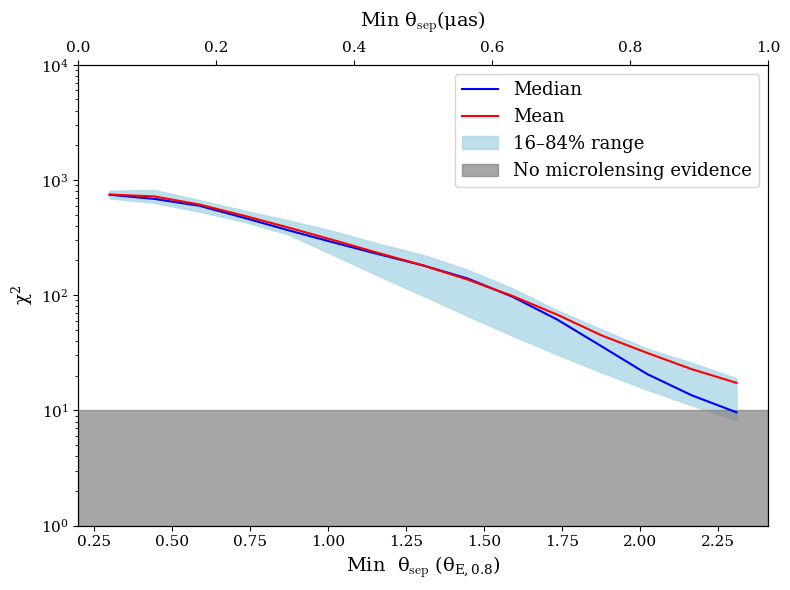

In [20]:
p16= np.array(np.percentile(chi_full, 16, axis=1), dtype=float)
p84 = np.array(np.percentile(chi_full, 84, axis=1), dtype=float)
#xlim_real=1.2*xlim
fig,ax = plt.subplots(figsize=(8,6))

ax.plot(impact_params / theta_E_8, np.percentile(chi_full, 50, axis=1), color='blue', label='Median')
ax.plot(impact_params / theta_E_8, chi_mean, label='Mean', color='red')
ax.fill_between(impact_params / theta_E_8, p16, p84,  alpha=0.8, label='16–84% range', color='lightblue')

ax_top = ax.twiny() # for top axis
ax_top.spines["top"].set_position(("axes", 1))
ax_top.set_xlabel(r'Min $\theta_{\text{sep}}$($\mu$as)',  fontsize=14, labelpad=10)
#ax_top.set_xlim(0,xlim_real*theta_E_8[0]*rad_to_arcsec)

ax_top.tick_params(axis='both', which='major', labelsize=11)
ax.tick_params(axis='both', which='major', labelsize=11)

ax.axhspan(0,10, label='No microlensing evidence', alpha=.7, color='gray')
ax.set_ylabel(r'$\chi^2$', fontsize=13)
ax.set_xlabel(r'Min  $\theta_{\text{sep}}$ ($\theta_{E, 0.8}$)', fontsize=14)
ax.set_yscale('log')
#ax.set_xlim(.2, xlim_real)
ax.set_ylim(1, 1e4)
ax.legend(fontsize=13)
fig.tight_layout() # 5 years

#### Uncertainties 

In [21]:
# load in the averages
uncert_rads_avg =np.array(np.percentile(uncert_full[:,:,0], 50, axis=1))
uncert_mass_avg =np.array(np.percentile(uncert_full[:,:,1], 50, axis=1))
uncert_xpos_avg =np.array(np.percentile(uncert_full[:,:,2], 50, axis=1))
uncert_ypos_avg =np.array(np.percentile(uncert_full[:,:,3], 50, axis=1))
uncert_xvel_avg =np.array(np.percentile(uncert_full[:,:,4], 50, axis=1))
uncert_yvel_avg =np.array(np.percentile(uncert_full[:,:,5], 50, axis=1))
s_to_yr = 1 / (365.25 * 86400)  


In [22]:
import pandas


In [23]:
df=pd.DataFrame((np.array((impact_params/theta_E_8, uncert_rads_avg, uncert_mass_avg, 
                        uncert_xpos_avg, uncert_ypos_avg, uncert_xvel_avg, uncert_yvel_avg,
                        acc_sigma_50* rad_to_arcsec / s_to_yr**2, acc_sigma_res_50*rad_to_arcsec / s_to_yr**2)).T),
                        columns=['impact_param', 'uncert_rad', 'uncert_mass', 'uncert_xpos', 'uncert_ypos', 'uncert_xvel', 'uncert_yvel', 
                                 'acc_sigma [mas/yr^2]', 'acc_sigma_res [mas/yr^2]'])

df

,impact_param,uncert_rad,uncert_mass,uncert_xpos,uncert_ypos,uncert_xvel,uncert_yvel,acc_sigma [mas/yr^2],acc_sigma_res [mas/yr^2]
0,0.3,0.00038,0.00928,0.293268,0.318041,235.36158,580.926378,0.026482,0.034858
1,0.44359,0.000426,0.009675,0.286942,0.308201,259.670839,570.601471,0.020692,0.028539
2,0.587179,0.000438,0.009847,0.299566,0.246027,268.763268,549.458734,0.023677,0.032653
3,0.730769,0.000439,0.010036,0.322647,0.276221,286.898222,557.777062,0.028399,0.038985
4,0.874359,0.000426,0.010405,0.327102,0.247351,284.606941,499.775314,0.034378,0.046702
5,1.017949,0.000416,0.011766,0.352329,0.245931,311.138801,479.796058,0.036186,0.049495
6,1.161538,0.000405,0.014167,0.388414,0.282014,363.387858,509.862387,0.03739,0.051256
7,1.305128,0.000384,0.016544,0.429603,0.337318,415.078176,608.000359,0.040568,0.055402
8,1.448718,0.000353,0.017641,0.473031,0.396049,484.762418,763.760329,0.039865,0.054357
9,1.592308,0.000327,0.018951,0.526913,0.473763,557.939515,905.053611,0.040163,0.055381


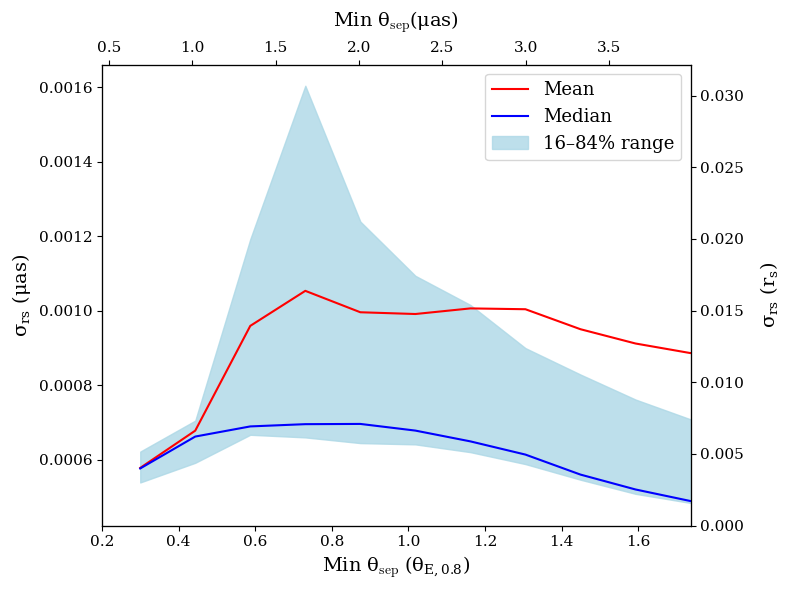

In [63]:
p16 = np.array(np.percentile(uncert_full[:,:,0], 16, axis=1), dtype=float)
p84= np.array(np.percentile(uncert_full[:,:,0], 84, axis=1), dtype=float)
mean= np.array(np.mean(uncert_full[:,:,0], axis=1), dtype=float)

fig,ax = plt.subplots(figsize=(8,6))
ylim=.0015
ax.plot(impact_params / theta_E_8, mean, label='Mean', color='red')
ax.plot(impact_params / theta_E_8, np.percentile(uncert_full[:,:,0], 50, axis=1), color='blue', label='Median')
ax.fill_between(impact_params / theta_E_8, p16, p84,  alpha=0.8, label='16–84% range', color='lightblue')

ticks_top=np.linspace(theta_E_8[0]*rad_to_arcsec, 8*theta_E_8[0]*rad_to_arcsec, 6) 

ax_top = ax.twiny() # for top axis
ax_top.spines["top"].set_position(("axes", 1))
ax_top.set_xlabel(r'Min $\theta_{\text{sep}}$($\mu$as)',  fontsize=14, labelpad=10)
ax_top.set_xlim(.2*theta_E_8[0]*rad_to_arcsec,xlim*theta_E_8[0]*rad_to_arcsec)

ax_right = ax.twinx() # for top axis
ax_right.spines["top"].set_position(("axes", 1))
ax_right.set_ylabel(r'$\sigma_{rs}$ ($r_s$)',  fontsize=14, labelpad=10)
ax_right.set_ylim(0,ylim/rad_mas)

ax_right.tick_params(axis='both', which='major', labelsize=11)
ax_top.tick_params(axis='both', which='major', labelsize=11)
ax.tick_params(axis='both', which='major', labelsize=11)

ax.set_xlabel(r'Min $\theta_{\text{sep}}$ ($\theta_{E, 0.8}$)', fontsize=14);
ax.set_ylabel(r"$\sigma_{rs}$ ($\mu$as)",  fontsize=14)
ax.set_xlim(.2, xlim)
#ax.set_ylim(0, ylim)

ax.legend(fontsize=13)
fig.tight_layout()

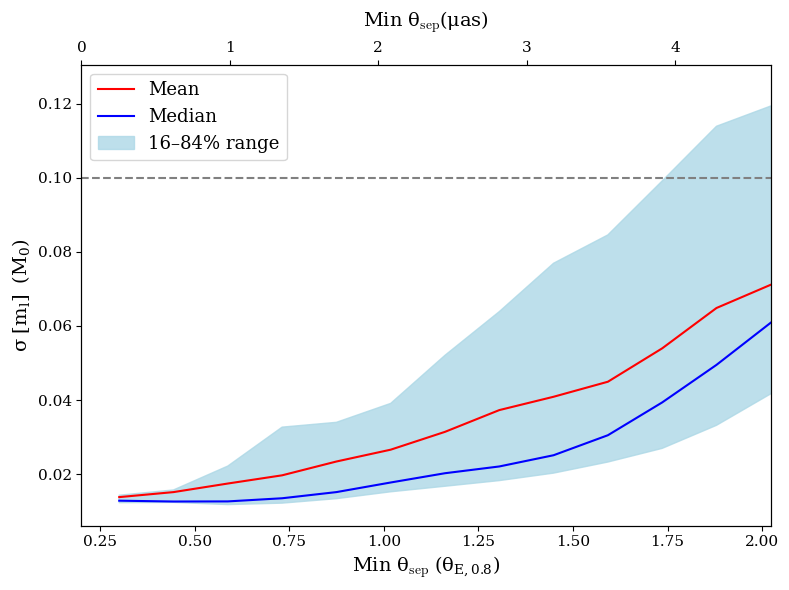

In [113]:
p16 = np.array(np.percentile(uncert_full[:,:,1], 16, axis=1), dtype=float)
p84 = np.array(np.percentile(uncert_full[:,:,1], 84, axis=1), dtype=float)
mean=np.array(np.mean(uncert_full[:,:,1], axis=1), dtype=float)
fig,ax = plt.subplots(figsize=(8,6))
ax.plot(impact_params / theta_E_8, mean,  label='Mean', color='red')
ax.plot(impact_params / theta_E_8, np.percentile(uncert_full[:,:,1], 50, axis=1), color='blue', label='Median')
ax.fill_between(impact_params / theta_E_8, p16, p84,  alpha=0.8, label='16–84% range', color='lightblue')

ax_top = ax.twiny() # for top axis
ax_top.spines["top"].set_position(("axes", 1))
#ax_top.set_xticks(ticks_top, minor=False);
ax_top.set_xlabel(r'Min $\theta_{\text{sep}}$($\mu$as)',  fontsize=14, labelpad=10)
ax_top.set_xlim(0,xlim*theta_E_8[0]*rad_to_arcsec)
ax.axhline(0.1, linestyle='dashed', color='gray')


ax_top.tick_params(axis='both', which='major', labelsize=11)
ax.tick_params(axis='both', which='major', labelsize=11)

ax.set_xlabel(r'Min $\theta_{\text{sep}}$ ($\theta_{E, 0.8}$)', fontsize=14)
ax.set_ylabel(r"$\sigma \ [m_l]\ \ (M_0)$", fontsize=14)
ax.set_xlim(.2, xlim)
#ax.set_ylim(0, .22)
ax.legend(fontsize=13)
fig.tight_layout()

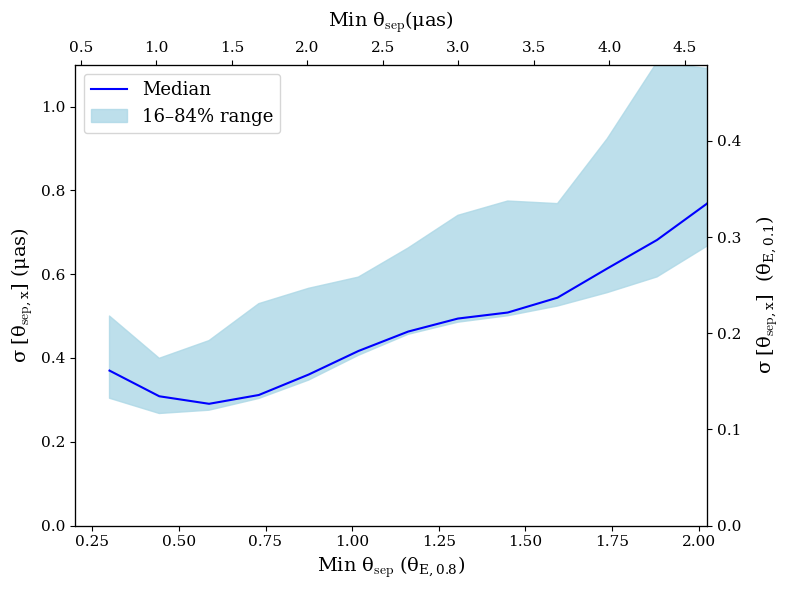

In [114]:
p16 = np.array(np.percentile(uncert_full[:,:,2], 16, axis=1), dtype=float)
p84= np.array(np.percentile(uncert_full[:,:,2], 84, axis=1), dtype=float)
fig,ax = plt.subplots(figsize=(8,6))

ax.plot(impact_params / theta_E_8, np.percentile(uncert_full[:,:,2], 50, axis=1), color='blue', label='Median')
ax.fill_between(impact_params / theta_E_8, p16, p84,  alpha=0.8, label='16–84% range', color='lightblue')
ylim=1.1
ax_top = ax.twiny() # for top axis
ax_top.spines["top"].set_position(("axes", 1))
#ax_top.set_xticks(ticks_top, minor=False);
ax_top.set_xlabel(r'Min $\theta_{\text{sep}}$($\mu$as)',  fontsize=14, labelpad=10)
ax_top.set_xlim(.2*theta_E_8[0]*rad_to_arcsec,xlim*theta_E_8[0]*rad_to_arcsec)

ax_right = ax.twinx() # for top axis
ax_right.spines["top"].set_position(("axes", 1))
#ax_top.set_xticks(ticks_top, minor=False);
ax_right.set_ylabel(r'$\sigma \ [\theta_{\text{sep},x}]$  ($\theta_{E, 0.1}$)',  fontsize=14, labelpad=10)
ax_right.set_ylim(0,ylim/(rad_to_arcsec*theta_E_8[0]))

ax_right.tick_params(axis='both', which='major', labelsize=11)
ax_top.tick_params(axis='both', which='major', labelsize=11)
ax.tick_params(axis='both', which='major', labelsize=11)

ax.set_xlabel(r'Min $\theta_{\text{sep}}$ ($\theta_{E, 0.8}$)', fontsize=14)
ax.set_ylabel(r"$\sigma \ [\theta_{\text{sep},x}]$ ($\mu$as)", fontsize=14)
ax.legend()
ax.set_xlim(.2, xlim)

ax.set_ylim(0, ylim)
ax.legend(fontsize=13)
fig.tight_layout()

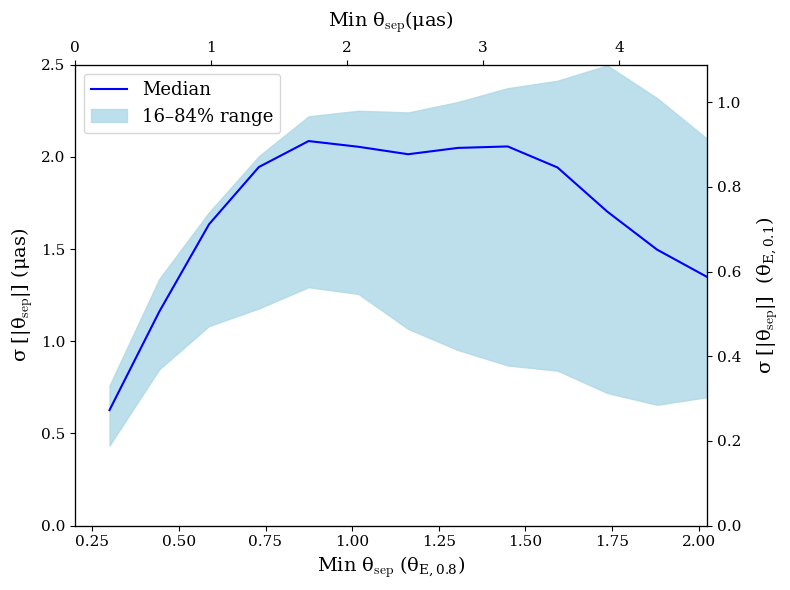

In [115]:
dist_uncert=(np.array(uncert_full[:,:,2])**2+np.array(uncert_full[:,:,3])**2)**(0.5)
p16 = np.array(np.percentile(dist_uncert, 16, axis=1), dtype=float)
p84= np.array(np.percentile(dist_uncert, 84, axis=1), dtype=float)
fig,ax = plt.subplots(figsize=(8,6))

ax.plot(impact_params / theta_E_8, (impact_params/theta_E_8)/np.percentile(dist_uncert, 50, axis=1), color='blue', label='Median')
ax.fill_between(impact_params / theta_E_8, (impact_params/theta_E_8)/p16, (impact_params/theta_E_8)/p84,  alpha=0.8, label='16–84% range', color='lightblue')
ylim=2.5
ax_top = ax.twiny() # for top axis
ax_top.spines["top"].set_position(("axes", 1))
#ax_top.set_xticks(ticks_top, minor=False);
ax_top.set_xlabel(r'Min $\theta_{\text{sep}}$($\mu$as)',  fontsize=14, labelpad=10)
ax_top.set_xlim(0,xlim*theta_E_8[0]*rad_to_arcsec)

ax_right = ax.twinx() # for top axis
ax_right.spines["top"].set_position(("axes", 1))
#ax_top.set_xticks(ticks_top, minor=False);
ax_right.set_ylabel(r'$\sigma \ [|\theta_{\text{sep}}|]$  ($\theta_{E, 0.1}$)',  fontsize=14, labelpad=10)
ax_right.set_ylim(0,ylim/(rad_to_arcsec*theta_E_8[0]))

ax_right.tick_params(axis='both', which='major', labelsize=11)
ax_top.tick_params(axis='both', which='major', labelsize=11)
ax.tick_params(axis='both', which='major', labelsize=11)

ax.set_xlabel(r'Min $\theta_{\text{sep}}$ ($\theta_{E, 0.8}$)', fontsize=14)
ax.set_ylabel(r"$\sigma \ [|\theta_{\text{sep}}|]$ ($\mu$as)", fontsize=14)
ax.legend()
ax.set_xlim(.2, xlim)
ax.set_ylim(0, ylim)
ax.legend(fontsize=13)
fig.tight_layout()

In [1]:
(.3**2+.4**2)**(.5)

0.5

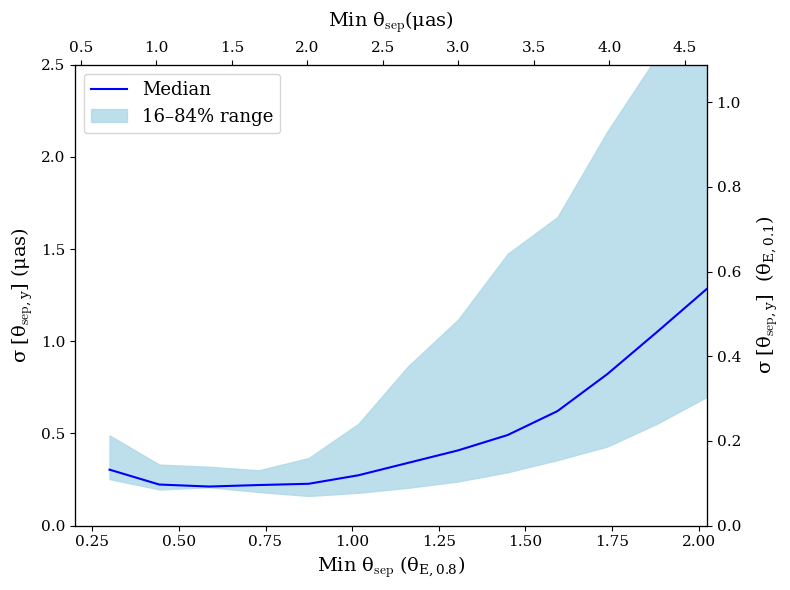

In [116]:
p16 = np.array(np.percentile(uncert_full[:,:,3], 16, axis=1), dtype=float)
p84 = np.array(np.percentile(uncert_full[:,:,3], 84, axis=1), dtype=float)
fig,ax = plt.subplots(figsize=(8,6))
ylim=2.5

ax.plot(impact_params / theta_E_8, np.percentile(uncert_full[:,:,3], 50, axis=1), color='blue', label='Median')
ax.fill_between(impact_params / theta_E_8, p16, p84,  alpha=0.8, label='16–84% range', color='lightblue')

ax_top = ax.twiny() # for top axis
ax_top.spines["top"].set_position(("axes", 1))
#ax_top.set_xticks(ticks_top, minor=False);
ax_top.set_xlabel(r'Min $\theta_{\text{sep}}$($\mu$as)',  fontsize=14, labelpad=10)
ax_top.set_xlim(.2*theta_E_8[0]*rad_to_arcsec,xlim*theta_E_8[0]*rad_to_arcsec)

ax_right = ax.twinx() # for top axis
ax_right.spines["top"].set_position(("axes", 1))
#ax_top.set_xticks(ticks_top, minor=False);
ax_right.set_ylabel(r'$\sigma \ [\theta_{\text{sep},y}]$  ($\theta_{E, 0.1}$)',  fontsize=14, labelpad=10)
ax_right.set_ylim(0,ylim/(rad_to_arcsec*theta_E_8[0]))

ax_right.tick_params(axis='both', which='major', labelsize=11)
ax_top.tick_params(axis='both', which='major', labelsize=11)
ax.tick_params(axis='both', which='major', labelsize=11)

ax.set_xlabel(r'Min $\theta_{\text{sep}}$ ($\theta_{E, 0.8}$)', fontsize=14)
ax.set_ylabel(r"$\sigma \ [\theta_{\text{sep},y}]$ ($\mu$as)", fontsize=14)
ax.set_xlim(.2, xlim)

ax.set_ylim(0, ylim)
ax.legend(fontsize=13)
fig.tight_layout()

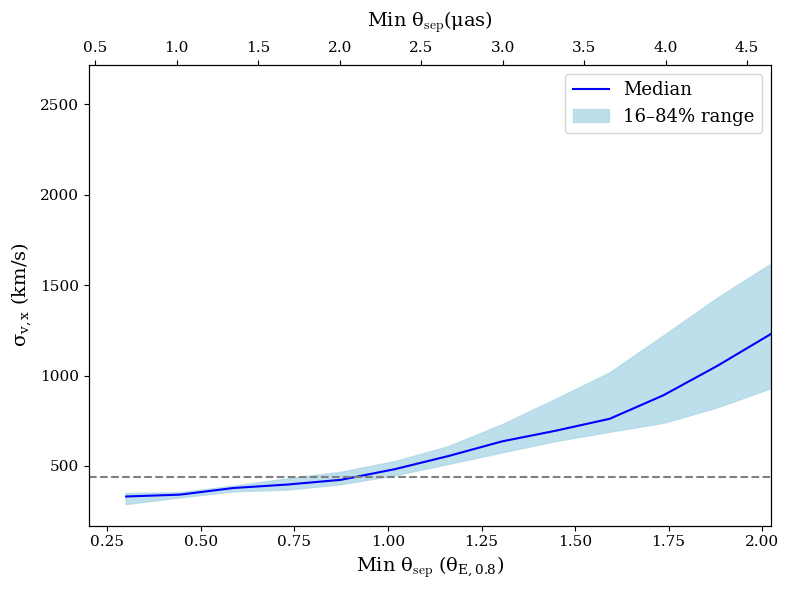

In [117]:
p16 = np.array(np.percentile(uncert_full[:,:,4], 16, axis=1), dtype=float)
p84 = np.array(np.percentile(uncert_full[:,:,4], 84, axis=1), dtype=float)

fig,ax = plt.subplots(figsize=(8,6)) #actual here has mean around 400 km/s and std 207.2 km/s
ylim=5.1

ax.plot(impact_params / theta_E_8, np.percentile(uncert_full[:,:,4], 50, axis=1),color='blue', label='Median')
ax.fill_between(impact_params / theta_E_8, p16, p84,  alpha=0.8, label='16–84% range', color='lightblue')

ax_top = ax.twiny() # for top axis
ax_top.spines["top"].set_position(("axes", 1))
#ax_top.set_xticks(ticks_top, minor=False);
ax_top.set_xlabel(r'Min $\theta_{\text{sep}}$($\mu$as)',  fontsize=14, labelpad=10)
ax_top.set_xlim(.2*theta_E_8[0]*rad_to_arcsec,xlim*theta_E_8[0]*rad_to_arcsec)

ax.axhline(np.sqrt(bulk_vel**2+vel_disp**2), linestyle='dashed', color='gray')

ax_top.tick_params(axis='both', which='major', labelsize=11)
ax.tick_params(axis='both', which='major', labelsize=11)

ax.set_xlabel(r'Min $\theta_{\text{sep}}$ ($\theta_{E, 0.8}$)', fontsize=14)
ax.set_ylabel(r"$\sigma_{v, x}$ (km/s)", fontsize=14)
#plt.xlim(0.4, 2.5)
ax.set_xlim(.2, xlim)

ax.legend(fontsize=13)
fig.tight_layout()

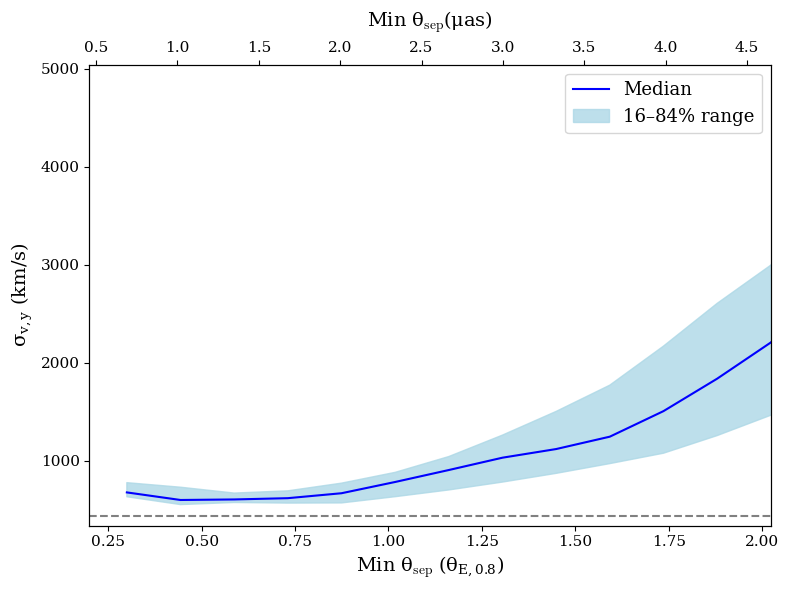

In [118]:
# mean 0 and std 181.4 km/s
p16 = np.array(np.percentile(uncert_full[:,:,5], 16, axis=1), dtype=float)
p84 = np.array(np.percentile(uncert_full[:,:,5], 84, axis=1), dtype=float)

fig,ax = plt.subplots(figsize=(8,6)) 
ylim=3.7

ax.plot(impact_params / theta_E_8, np.percentile(uncert_full[:,:,5], 50, axis=1), color='blue', label='Median')
ax.fill_between(impact_params / theta_E_8, p16, p84,  alpha=0.8, label='16–84% range', color='lightblue')
ax.axhline(np.sqrt(bulk_vel**2+vel_disp**2), linestyle='dashed', color='gray')

ax_top = ax.twiny() # for top axis
ax_top.spines["top"].set_position(("axes", 1))
#ax_top.set_xticks(ticks_top, minor=False);
ax_top.set_xlabel(r'Min $\theta_{\text{sep}}$($\mu$as)',  fontsize=14, labelpad=10)
ax_top.set_xlim(.2*theta_E_8[0]*rad_to_arcsec,xlim*theta_E_8[0]*rad_to_arcsec)

ax_top.tick_params(axis='both', which='major', labelsize=11)
ax.tick_params(axis='both', which='major', labelsize=11)

ax.set_xlabel(r'Min $\theta_{\text{sep}}$ ($\theta_{E, 0.8}$)', fontsize=14)
ax.set_ylabel(r"$\sigma_{v, y}$ (km/s)", fontsize=14)
ax.set_xlim(.2, xlim)

#ax.set_ylim(0, ylim)
ax.legend(fontsize=13)
fig.tight_layout()

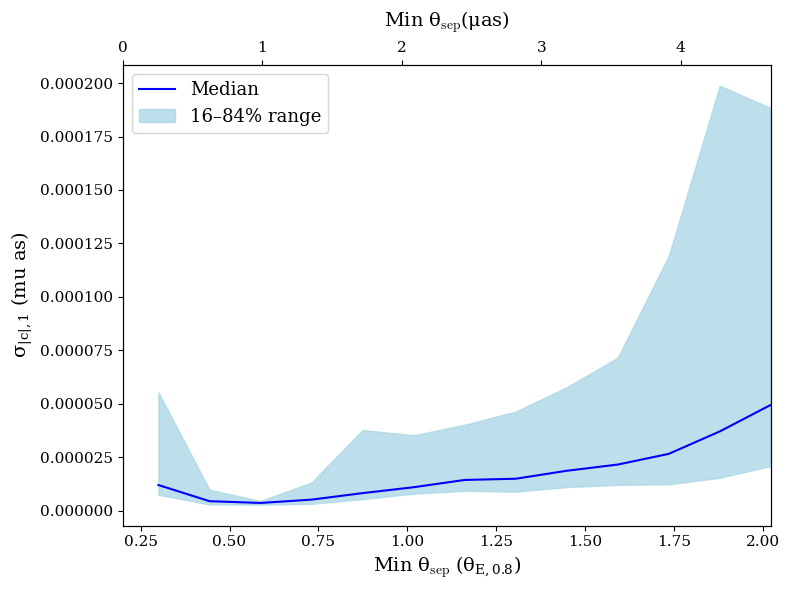

In [119]:
# mean 0 and std 181.4 km/s
p16 = sigma_cent1_16*rad_to_arcsec**4
p84 = sigma_cent1_84*rad_to_arcsec**4

fig,ax = plt.subplots(figsize=(8,6)) 
ylim=3.7

ax.plot(impact_params / theta_E_8, sigma_cent1_50*rad_to_arcsec**4, color='blue', label='Median')
ax.fill_between(impact_params / theta_E_8, p16, p84,  alpha=0.8, label='16–84% range', color='lightblue')

ax_top = ax.twiny() # for top axis
ax_top.spines["top"].set_position(("axes", 1))
#ax_top.set_xticks(ticks_top, minor=False);
ax_top.set_xlabel(r'Min $\theta_{\text{sep}}$($\mu$as)',  fontsize=14, labelpad=10)
ax_top.set_xlim(0,xlim*theta_E_8[0]*rad_to_arcsec)

ax_top.tick_params(axis='both', which='major', labelsize=11)
ax.tick_params(axis='both', which='major', labelsize=11)

ax.set_xlabel(r'Min $\theta_{\text{sep}}$ ($\theta_{E, 0.8}$)', fontsize=14)
ax.set_ylabel(r"$\sigma_{|c|, 1}$ (mu as)", fontsize=14)
ax.set_xlim(.2, xlim)

#ax.set_ylim(0, ylim)
ax.legend(fontsize=13)
fig.tight_layout()

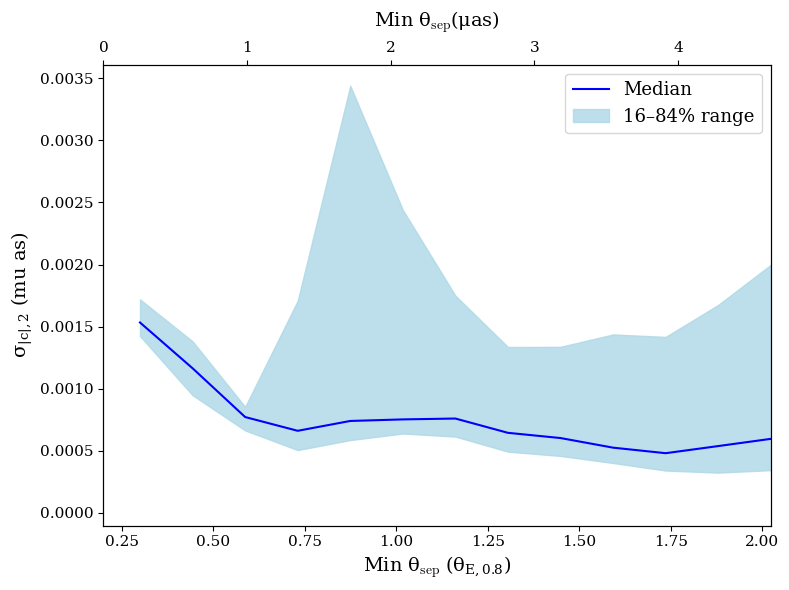

In [120]:
# mean 0 and std 181.4 km/s
p16 = sigma_cent2_16*rad_to_arcsec**2
p84 = sigma_cent2_84*rad_to_arcsec**2

fig,ax = plt.subplots(figsize=(8,6)) 
ylim=3.7

ax.plot(impact_params / theta_E_8, sigma_cent2_50*rad_to_arcsec**2, color='blue', label='Median')
ax.fill_between(impact_params / theta_E_8, p16, p84,  alpha=0.8, label='16–84% range', color='lightblue')

ax_top = ax.twiny() # for top axis
ax_top.spines["top"].set_position(("axes", 1))
#ax_top.set_xticks(ticks_top, minor=False);
ax_top.set_xlabel(r'Min $\theta_{\text{sep}}$($\mu$as)',  fontsize=14, labelpad=10)
ax_top.set_xlim(0,xlim*theta_E_8[0]*rad_to_arcsec)

ax_top.tick_params(axis='both', which='major', labelsize=11)
ax.tick_params(axis='both', which='major', labelsize=11)

ax.set_xlabel(r'Min $\theta_{\text{sep}}$ ($\theta_{E, 0.8}$)', fontsize=14)
ax.set_ylabel(r"$\sigma_{|c|, 2}$ (mu as)", fontsize=14)
ax.set_xlim(.2, xlim)
#ax.set_ylim(0, ylim)
ax.legend(fontsize=13)
fig.tight_layout()

### Probabilities

Now answering the question "will we ever see any such lens trajectories?"

In [4]:
def expected_time_to_encounter(stellar_density, v_bulk, v_bulk_err, vel_disp, vel_disp_err, L_min, 
                               B_matrix, redshift, lens_dist, n_samples=100000,seed=None, L_max=None, cutoff=4.5*theta_E_8[0]):
    """
    Not specific to a 0.1 solar mass star, this is general
    get expected time for a star to come within L_min of the quasar, given surface density near the quasar and velocity distributions
    inputs:
        stellar_density: surface number density of stars (in 1/rad^2)
        v_bulk: vel of the galaxy in km/s, assuemd to be entirely in the x-direction
        vel_disp: km/s
        L_min: minimum impact distance, ie how close we require our star to be to the quasar
        n_samples: number of samples to estimate the avg transverse speed
    returns:
        t_exp_yr: time until the next close encounter in years
        encounter_rate: inverse of t_exp_yr, num encounters/yr
    """
    
    rng = np.random.default_rng(seed)
    seconds_year=31536000
    km_to_cm = 1e5
    
    # angular => distances in cm
    L_min_phys = L_min * D_l
    if L_max is not None:
        L_max_phys = L_max * D_l
    else:
        L_max_phys = None

    vel_angle = rng.uniform(0, 2*np.pi, size=n_samples)

    # sample bulk velocity and dispersion for each star
    # assume bulk along x, plus Gaussian scatter
    v_bulk_samples = rng.normal(loc=v_bulk, scale=v_bulk_err, size=n_samples)
    vel_disp_samples = rng.normal(loc=0, scale=np.sqrt(vel_disp**2 + vel_disp_err**2), size=n_samples)

    # total velocity components
    v_x_kms = v_bulk_samples + vel_disp_samples * np.cos(vel_angle)
    v_y_kms = vel_disp_samples * np.sin(vel_angle)

    # convert to cm/s
    v_rest = np.stack([v_x_kms, v_y_kms], axis=-1) * km_to_cm  # shape (n_samples, 2)

    # apply lensing/angular conversion
    v_ang = np.array([get_velocities(v, B_matrix, redshift, lens_dist) for v in v_rest])
    v_phys = v_ang * lens_dist

    # transverse speed per sample
    v_perp = np.linalg.norm(v_phys, axis=1)  # shape (n_samples,)
    mean_ang_v=(np.mean(np.linalg.norm(v_ang, axis=1)*365.25*24*3600)) #rad/year
    
    # effective width of encounter band
    if L_max_phys is None:
        delta_L = L_min_phys  # encounter within radius L_min
    else:
        delta_L = (L_max_phys - L_min_phys)  # encounter between L_min and L_max

    # per-star area swept per second 
    rate_per_star = 2 * delta_L * v_perp
    encounter_rate = stellar_density * np.mean(rate_per_star)
    t_expected = 1.0 / encounter_rate
    t_exp_yr=t_expected/seconds_year
    char_time = 2 * np.sqrt(cutoff**2 - L_min**2) / mean_ang_v # path length inside a circle of radius cutoff is sqrt(cutoff**2-L_min**2)

    
    return t_exp_yr, 1/t_exp_yr, char_time


In [11]:
# kappa values are here: https://arxiv.org/pdf/2303.11987
kappa_star= 0.04 #dimensionless, we want this over kappa_crit
kappa_crit=(c**2/(4*np.pi*G))*(D_s/(D_l*D_ls)) # g/cm^2
Sigma_star=kappa_star*kappa_crit
avg_star_mass=.5*u.solMass.to(u.g) # ~typical mass of a star
n=(Sigma_star/avg_star_mass) #stars/cm^2
expected_time_to_encounter(n, bulk_vel, bulk_vel_err, vel_disp, vel_disp_err, 4.5*theta_E_8[0], B_matrix, z_l, D_l, L_max=None)

(np.float64(29.769150934719857),
 np.float64(0.0335918213520056),
 np.float64(0.0))

In [43]:
# calculate it all for a few example impact parameters
impact_params_time=np.array([0.3, 0.730769, 1.161538, 1.592308, 2.023077, 
                             2.453846, 2.884615, 3.315385, 3.746154, 4.176923])
# years between events
years_bet=[]

#how long such an event lasts
years_last=[]
for i in impact_params_time:
    exp, _, char = expected_time_to_encounter(n, bulk_vel, bulk_vel_err, vel_disp, vel_disp_err, i*theta_E_8[0], B_matrix, z_l, D_l, L_max=None)
    years_bet.append(exp)
    years_last.append(char)

In [45]:
df=pd.DataFrame((np.array((impact_params_time, years_bet, years_last)).T))
df

,0,1,2
0,0.300000,446.262512,49.234977
1,0.730769,182.875178,48.602750
2,1.161538,115.158336,47.630600
3,1.592308,84.093770,46.160748
4,2.023077,66.219400,44.105929
5,2.453846,54.553436,41.358799
6,2.884615,46.318538,37.797360
7,3.315385,40.304517,33.301846
8,3.746154,35.725084,27.330196
9,4.176923,32.138345,18.409106
